# Pneumodetect — Pneumonia Detection from Chest X-ray Images

**Authors:** Asulkhan Aidarkhanov, Ravil Serikuly · **Group:** BDA-2401
**Course:** Machine Learning Algorithms, Astana IT University · **Instructor:** Assiya Karatay

## README

Pneumodetect is a decision-support prototype that estimates the probability of pneumonia on a frontal
(PA/AP) chest X-ray. It is a course project, **not a medical device**.

### Data (≈100k images, everything is fetched through APIs — nothing is uploaded by hand)

| Source | What we take | Access in this notebook |
|---|---|---|
| NIH ChestX-ray14 (Wang et al., 2017) | 112,120 frontal X-rays of 30,805 patients + metadata | Kaggle API, dataset `nih-chest-xrays/data` |
| RSNA Pneumonia Detection Challenge (Shih et al., 2019) | radiologist labels for 26,684 of the NIH images (label CSV only, no images) | Kaggle API, competition `rsna-pneumonia-detection-challenge` |
| RSNA → NIH mapping (RSNA, 2018) | links every RSNA image ID to its NIH file name | public HTTPS endpoint (JSON) |
| Kermany et al. (2018) | 5,856 paediatric X-rays, Normal / Bacterial / Viral | Kaggle API, dataset `paultimothymooney/chest-xray-pneumonia` |

RSNA images *are* NIH images, so we never use them twice: RSNA contributes only its (more reliable) labels.

### How to run

**Option A — Kaggle Notebooks (recommended: datasets are attached by the API without downloading, free GPU).**
1. Sign in to Kaggle and press *Join / I understand and accept* on the rules page of
   https://www.kaggle.com/competitions/rsna-pneumonia-detection-challenge (needed once, otherwise the API refuses the label file).
2. *Create → New Notebook → File → Import Notebook* and select this `.ipynb`.
3. *Settings*: Accelerator **GPU T4 ×2** (or P100), Internet **On**.
4. *Run All*.

**Option B — Google Colab.**
1. Kaggle → *Settings → API → Create New Token*; accept the RSNA competition rules (step A1).
2. In Colab open *Secrets* (key icon) and add either `KAGGLE_API_TOKEN` (new-style token) or `KAGGLE_USERNAME` +
   `KAGGLE_KEY` (legacy `kaggle.json`), and enable notebook access.
   Never paste the key into a cell — it would end up in the exported PDF.
3. *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.
4. Needs ~50 GB of free disk: the NIH archive (42 GB) is read **directly from the zip without extracting**
   once into a 224×224 cache (~5.6 GB); set `DELETE_NIH_ZIP_AFTER_CACHE = True` to free the space afterwards.

**Option C — local machine.** `pip install kagglehub tensorflow scikit-learn pandas pillow matplotlib tqdm requests`,
put your token in `~/.kaggle/kaggle.json`, run all cells (needs ~90 GB free for the extracted NIH data).

### Notebook structure (requirement IDs from the proposal)

1. Environment and GPU check — D4
2. Data acquisition through APIs — D1
3. Labels (variant *b*: radiologist-verified pneumonia vs. no pneumonia)
4. Train / validation / test split without patient leakage — D3
5. Image preprocessing to 224×224 — D2
6. Exploratory data analysis
7. Input pipeline, augmentation and class weights — D7, D8
8. Evaluation protocol: metrics on validation, NIH test and Kermany test — D10
9. Classical baselines: logistic regression and linear SVM on pixels and on frozen ResNet50 features — D11
10. CNN: ResNet50 transfer learning in two stages, callbacks, threshold tuning, success criteria — D5, D6, D9, D10, N5–N8
11. Grad-CAM heat maps, checked against RSNA radiologist boxes — N2
12. Three-class model: Normal / Bacterial / Viral — N1

The web interface (N3) is a separate notebook, `Pneumodetect_App.ipynb`: it loads the two saved models (N8) and serves
them with Gradio, so the demo starts in seconds without retraining.

## 1. Environment and GPU check (D4)

In [1]:
import subprocess, sys

# kagglehub is the official Kaggle API client for Python; Colab and Kaggle ship it, we only make sure it is recent.
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kagglehub>=0.3.4", "kaggle>=1.7.4"], check=False)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-U', 'kagglehub>=0.3.4', 'kaggle>=1.7.4'], returncode=0)

In [2]:
import io, json, os, random, re, threading, time, zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from tqdm.auto import tqdm

tf.get_logger().setLevel("ERROR")          # hide TensorFlow's internal retracing notices in the exported PDF
print("Python     :", sys.version.split()[0])
print("TensorFlow :", tf.__version__)
print("kagglehub  :", kagglehub.__version__)

Python     : 3.13.16
TensorFlow : 2.21.0
kagglehub  : 1.0.3


In [3]:
# ---- configuration ---------------------------------------------------------------------------------------------
SEED = 42
IMG_SIZE = 224            # D2: every image is resized to 224x224
BATCH_SIZE = 32
VAL_FRACTION = 0.15       # D3: validation split carved out of the training data (grouped by patient)

# Variant (b): positives are only radiologist-verified pneumonia (RSNA "Lung Opacity") or an explicit NIH "Pneumonia"
# label. NEGATIVE_POLICY decides which images count as negatives:
#   "all_non_pneumonia" - every image without pneumonia (No Finding + other diseases)  -> ~100k images
#   "normal_only"       - only images with no finding at all                           -> ~70k images
NEGATIVE_POLICY = os.environ.get("PNEUMODETECT_NEGATIVES", "all_non_pneumonia")

NIH_HANDLE = "nih-chest-xrays/data"
KERMANY_HANDLE = "paultimothymooney/chest-xray-pneumonia"
RSNA_COMPETITION = "rsna-pneumonia-detection-challenge"
RSNA_MAPPING_URL = ("https://s3.amazonaws.com/east1.public.rsna.org/AI/2018/"
                    "pneumonia-challenge-dataset-mappings_2018.json")

IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
try:
    import google.colab  # noqa: F401  (Kaggle images ship this package too, so Kaggle is checked first)
    IN_COLAB = not IN_KAGGLE
except ImportError:
    IN_COLAB = False

# "zip": read NIH images straight from the downloaded archive (Colab: avoids extracting 42 GB)
# "dir": use the folder returned by kagglehub (Kaggle Notebooks: attached, nothing is downloaded)
NIH_ACCESS = os.environ.get("PNEUMODETECT_NIH_ACCESS", "zip" if IN_COLAB else "dir")
DELETE_NIH_ZIP_AFTER_CACHE = False   # True frees 42 GB, but a second "Run all" would download it again

WORK_DIR = Path("/kaggle/working") if IN_KAGGLE else Path("/content") if IN_COLAB else Path.cwd()
CACHE_DIR = Path(os.environ.get("PNEUMODETECT_CACHE",
                                "/content/pneumodetect_cache" if IN_COLAB else "/tmp/pneumodetect_cache"))
CACHE_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print(f"Platform: {'Kaggle' if IN_KAGGLE else 'Colab' if IN_COLAB else 'local'} | NIH access: {NIH_ACCESS} | "
      f"negatives: {NEGATIVE_POLICY}")
print("Work dir :", WORK_DIR)
print("Cache dir:", CACHE_DIR)

Platform: Kaggle | NIH access: dir | negatives: all_non_pneumonia
Work dir : /kaggle/working
Cache dir: /tmp/pneumodetect_cache


In [4]:
# D4: training a CNN on ~100k images on a CPU is far too slow, so we check for a GPU before doing anything heavy.
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus)
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
        print("  ->", tf.config.experimental.get_device_details(gpu).get("device_name", gpu.name))
else:
    print("WARNING: no GPU found. Data preparation works on CPU, but switch the runtime to a GPU before training.")

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
  -> Tesla T4
  -> Tesla T4


## 2. Data acquisition through APIs (D1)

All data come from the Kaggle API (`kagglehub` / `kaggle` CLI) and one public HTTPS endpoint.
Credentials are read from Colab *Secrets* or `~/.kaggle/kaggle.json` and are never printed.

In [5]:
def setup_kaggle_credentials():
    # Make Kaggle credentials available to kagglehub and the kaggle CLI without printing them.
    if IN_KAGGLE:
        print("Running inside Kaggle: the API is already authenticated.")
        return
    has_env = os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY")
    has_file = (Path.home() / ".kaggle" / "kaggle.json").exists()
    if not (has_env or has_file or os.environ.get("KAGGLE_API_TOKEN")) and IN_COLAB:
        from google.colab import userdata
        def secret(name):
            try:
                return userdata.get(name)
            except Exception:
                return None
        if secret("KAGGLE_API_TOKEN"):
            os.environ["KAGGLE_API_TOKEN"] = secret("KAGGLE_API_TOKEN")
        elif secret("KAGGLE_USERNAME") and secret("KAGGLE_KEY"):
            os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = secret("KAGGLE_USERNAME"), secret("KAGGLE_KEY")
        else:
            raise RuntimeError("Add KAGGLE_API_TOKEN (or KAGGLE_USERNAME + KAGGLE_KEY) to Colab Secrets (see README).")
    print("Kaggle credentials configured (values hidden).")


setup_kaggle_credentials()

Running inside Kaggle: the API is already authenticated.


In [6]:
class DirSource:
    # Dataset files that are available as a folder (Kaggle mount or kagglehub download).
    def __init__(self, root):
        self.root = Path(root)
        self.files = sorted(str(p) for p in self.root.rglob("*") if p.is_file())

    def read(self, key):
        with open(key, "rb") as f:
            return f.read()


class ZipSource:
    # Dataset files read straight from a zip archive, without extracting it (thread-safe).
    def __init__(self, zip_path):
        self.zip_path = str(zip_path)
        self._local = threading.local()
        with zipfile.ZipFile(self.zip_path) as zf:
            self.files = sorted(n for n in zf.namelist() if not n.endswith("/"))

    def read(self, key):
        if not hasattr(self._local, "zf"):
            self._local.zf = zipfile.ZipFile(self.zip_path)
        return self._local.zf.read(key)


def find_file(source, filename):
    # Return the key of the (shallowest) file in `source` whose base name is `filename`.
    hits = [k for k in source.files if Path(k).name == filename and "__MACOSX" not in k]
    if not hits:
        raise FileNotFoundError(f"{filename} not found in {getattr(source, 'root', getattr(source, 'zip_path', ''))}")
    return min(hits, key=lambda k: (k.count("/"), k))


def read_csv_from(path, filename):
    # kagglehub may return a folder, the file itself or a zip with the file inside; handle all three.
    path = Path(path)
    if path.is_dir():
        source = DirSource(path)
    elif zipfile.is_zipfile(path):
        source = ZipSource(path)
    else:
        return pd.read_csv(path)
    names = [Path(k).name for k in source.files]
    key = find_file(source, filename) if filename in names else find_file(source, filename + ".zip")
    data = source.read(key)
    if key.endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(data)) as inner:
            data = inner.read(next(n for n in inner.namelist() if n.endswith(filename)))
    return pd.read_csv(io.BytesIO(data))

In [7]:
def get_nih_source():
    if NIH_ACCESS == "zip":
        zip_dir = CACHE_DIR / "nih_zip"
        zip_dir.mkdir(exist_ok=True)
        if not list(zip_dir.glob("*.zip")):
            print("Downloading the NIH archive through the Kaggle API (~42 GB, ~10-20 min on Colab)...")
            subprocess.run(["kaggle", "datasets", "download", "-d", NIH_HANDLE, "-p", str(zip_dir)], check=True)
        return ZipSource(next(zip_dir.glob("*.zip")))
    return DirSource(kagglehub.dataset_download(NIH_HANDLE))


t0 = time.time()
nih_src = get_nih_source()
kermany_src = DirSource(kagglehub.dataset_download(KERMANY_HANDLE))

# RSNA: only the radiologists' label file is needed, the images are the NIH ones.
rsna_classes = read_csv_from(
    kagglehub.competition_download(RSNA_COMPETITION, path="stage_2_detailed_class_info.csv"),
    "stage_2_detailed_class_info.csv")
rsna_boxes = read_csv_from(
    kagglehub.competition_download(RSNA_COMPETITION, path="stage_2_train_labels.csv"),
    "stage_2_train_labels.csv")

response = requests.get(RSNA_MAPPING_URL, timeout=300)
response.raise_for_status()
rsna_map = pd.DataFrame(response.json())

print(f"NIH files        : {len(nih_src.files):,}")
print(f"Kermany files    : {len(kermany_src.files):,}")
print(f"RSNA label rows  : {len(rsna_classes):,} ({rsna_classes.patientId.nunique():,} images)")
print(f"RSNA->NIH mapping: {len(rsna_map):,} entries")
print(f"Done in {time.time() - t0:.0f} s")

NIH files        : 112,128
Kermany files    : 17,591
RSNA label rows  : 30,227 (26,684 images)
RSNA->NIH mapping: 30,000 entries
Done in 162 s


## 3. Labels — variant (b)

**NIH + RSNA (adult patients).** NIH labels were mined from radiology reports by NLP and are noisy.
For the 26,684 NIH images re-read by radiologists in the RSNA challenge we use the RSNA label instead:

| Case | Label |
|---|---|
| RSNA *Lung Opacity* (pneumonia-like opacity confirmed by a radiologist) | 1 |
| RSNA *Normal* | 0 |
| RSNA *No Lung Opacity / Not Normal* (other disease, radiologist excluded pneumonia) | 0 if `all_non_pneumonia`, else dropped |
| not in RSNA, NIH label contains *Pneumonia* | 1 |
| not in RSNA, NIH *No Finding* | 0 |
| not in RSNA, NIH *Consolidation* / *Infiltration* without *Pneumonia* | **dropped** — pneumonia-like but never verified |
| not in RSNA, any other NIH finding | 0 if `all_non_pneumonia`, else dropped |

**Kermany (paediatric patients).** Folder name gives Normal / Pneumonia, the file name gives bacterial / viral
(used later for the 3-class task, N1).

In [8]:
# ---- NIH metadata ----
nih_meta = pd.read_csv(io.BytesIO(nih_src.read(find_file(nih_src, "Data_Entry_2017.csv"))))
nih_meta = nih_meta.rename(columns={"Image Index": "image_id", "Finding Labels": "findings",
                                    "Patient ID": "patient", "View Position": "view",
                                    "Patient Age": "age", "Patient Gender": "sex"})
nih_test_ids = set(nih_src.read(find_file(nih_src, "test_list.txt")).decode().split())
nih_meta["official_split"] = np.where(nih_meta.image_id.isin(nih_test_ids), "test", "train_val")

# ---- RSNA labels, attached to NIH file names through the mapping ----
rsna_cls = rsna_classes.drop_duplicates("patientId")[["patientId", "class"]]  # one row per box -> one per image
rsna_cls = rsna_cls.merge(rsna_map[["subset_img_id", "img_id"]], left_on="patientId",
                          right_on="subset_img_id", how="left")
unmapped = rsna_cls.img_id.isna().sum()
print(f"RSNA images: {len(rsna_cls):,} | not found in the mapping: {unmapped}")
assert unmapped == 0, "every RSNA label must map to exactly one NIH image"
assert rsna_cls.img_id.is_unique

nih_meta = nih_meta.merge(rsna_cls[["img_id", "class"]].rename(columns={"img_id": "image_id", "class": "rsna_class"}),
                          on="image_id", how="left")
print(rsna_cls["class"].value_counts().to_string())

RSNA images: 26,684 | not found in the mapping: 0
class
No Lung Opacity / Not Normal    11821
Normal                           8851
Lung Opacity                     6012


In [9]:
PNEUMONIA_LIKE = {"Consolidation", "Infiltration"}


def nih_label(findings, rsna_class, negative_policy=NEGATIVE_POLICY):
    # Variant (b) labelling rule. Returns (label or None if dropped, reason).
    keep_other = negative_policy == "all_non_pneumonia"
    if isinstance(rsna_class, str):                       # a radiologist looked at this image
        if rsna_class == "Lung Opacity":
            return 1, "RSNA: lung opacity"
        if rsna_class == "Normal":
            return 0, "RSNA: normal"
        return (0 if keep_other else None), "RSNA: not normal, no opacity"
    labels = set(findings.split("|"))
    if "Pneumonia" in labels:
        return 1, "NIH: pneumonia"
    if labels == {"No Finding"}:
        return 0, "NIH: no finding"
    if labels & PNEUMONIA_LIKE:
        return None, "NIH: unverified consolidation/infiltration"
    return (0 if keep_other else None), "NIH: other finding"


assert nih_label("Pneumonia|Effusion", None) == (1, "NIH: pneumonia")
assert nih_label("Infiltration", None)[0] is None
assert nih_label("Infiltration", "Lung Opacity") == (1, "RSNA: lung opacity")
assert nih_label("Nodule", "No Lung Opacity / Not Normal", "normal_only")[0] is None
assert nih_label("Nodule", None, "all_non_pneumonia") == (0, "NIH: other finding")

nih_meta[["label", "reason"]] = [nih_label(f, r) for f, r in zip(nih_meta.findings, nih_meta.rsna_class)]
reasons = (nih_meta.groupby("reason", dropna=False)
           .agg(images=("image_id", "size"), label=("label", "first"))
           .sort_values("images", ascending=False))
reasons["used"] = reasons.label.notna()
display(reasons)

,images,label,used
reason,,,
NIH: no finding,53692,0.0,True
NIH: other finding,21007,0.0,True
"RSNA: not normal, no opacity",11821,0.0,True
NIH: unverified consolidation/infiltration,10114,None,False
RSNA: normal,8851,0.0,True
RSNA: lung opacity,6012,1.0,True
NIH: pneumonia,623,1.0,True


In [10]:
# ---- attach image file keys to NIH rows ----
nih_files = {Path(k).name: k for k in nih_src.files if k.endswith(".png")}
nih_meta["file_key"] = nih_meta.image_id.map(nih_files)
missing = nih_meta.file_key.isna().sum()
print(f"NIH images listed in metadata but missing on disk: {missing}")

nih_df = nih_meta[nih_meta.label.notna() & nih_meta.file_key.notna()].copy()
nih_df = pd.DataFrame({
    "image_id": nih_df.image_id, "source": "NIH", "file_key": nih_df.file_key,
    "label": nih_df.label.astype(int), "subtype": np.where(nih_df.label == 1, "pneumonia", "no_pneumonia"),
    "patient_id": "nih_" + nih_df.patient.astype(str), "label_source": np.where(nih_df.rsna_class.notna(), "RSNA", "NIH"),
    "official_split": nih_df.official_split,
})
print(f"NIH images used: {len(nih_df):,}")

NIH images listed in metadata but missing on disk: 0
NIH images used: 102,006


In [11]:
# ---- Kermany ----
def kermany_table(source):
    rows, seen = [], set()
    for key in source.files:
        parts = Path(key).parts
        if "__MACOSX" in parts or not key.lower().endswith((".jpeg", ".jpg", ".png")):
            continue
        split = next((p for p in reversed(parts) if p in ("train", "val", "test")), None)
        cls = next((p for p in reversed(parts) if p in ("NORMAL", "PNEUMONIA")), None)
        name = parts[-1]
        if split is None or cls is None or (split, cls, name) in seen:   # the Kaggle zip contains a duplicate copy
            continue
        seen.add((split, cls, name))
        person = re.match(r"(person\d+)_", name)
        if cls == "PNEUMONIA":
            subtype = "bacterial" if "bacteria" in name.lower() else "viral" if "virus" in name.lower() else "unknown"
        else:
            subtype = "normal"
        rows.append({
            "image_id": f"{split}/{cls}/{name}", "source": "Kermany", "file_key": key,
            "label": int(cls == "PNEUMONIA"), "subtype": subtype,
            # Pneumonia files carry a patient id (person123_bacteria_456.jpeg); normal ones do not (IM-0001-0001.jpeg),
            # so each normal image is its own group = plain stratified split (limitation noted in the proposal).
            # The official val folder is merged into train, so train/val share one id space ("trainval").
            "patient_id": (f"kermany_{'test' if split == 'test' else 'trainval'}_{person.group(1)}" if person
                           else f"kermany_img_{split}_{name}"),
            "label_source": "Kermany",
            "official_split": "test" if split == "test" else "train_val",   # the 16 official val images join train
        })
    return pd.DataFrame(rows)


kermany_df = kermany_table(kermany_src)
print(f"Kermany images: {len(kermany_df):,}")
display(pd.crosstab(kermany_df.official_split, kermany_df.subtype, margins=True))

Kermany images: 5,856


subtype,bacterial,normal,viral,All
official_split,,,,
test,242,234,148,624
train_val,2538,1349,1345,5232
All,2780,1583,1493,5856


## 4. Train / validation / test split without leakage (D3)

* **Test sets stay untouched**: the official NIH patient-wise test list and the official Kermany test folder (624 images).
  They are used once, for the final evaluation.
* **Validation** (≈15 %) is carved out of the training pool with `StratifiedGroupKFold`: groups = patients, so one
  patient never appears in two splits, and the pneumonia ratio is kept the same in train and validation.

In [12]:
def split_train_val(df, val_fraction=VAL_FRACTION, seed=SEED):
    df = df.copy()
    df["split"] = np.where(df.official_split == "test", "test", "train")
    pool = df[df.split == "train"]
    n_splits = max(2, round(1 / val_fraction))
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    _, val_idx = next(sgkf.split(pool, pool.label, groups=pool.patient_id))
    df.loc[pool.index[val_idx], "split"] = "val"
    return df


data = pd.concat([split_train_val(nih_df), split_train_val(kermany_df)], ignore_index=True)

# ---- leakage checks ----
assert data.image_id.is_unique, "duplicate images"
for source, part in data.groupby("source"):
    patients = {s: set(part.loc[part.split == s, "patient_id"]) for s in ("train", "val", "test")}
    for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
        overlap = patients[a] & patients[b]
        assert not overlap, f"{source}: {len(overlap)} patients in both {a} and {b}"
print("No patient appears in more than one split.")

summary = data.pivot_table(index=["source", "split"], columns="label", values="image_id", aggfunc="count",
                           fill_value=0).rename(columns={0: "no pneumonia", 1: "pneumonia"})
summary["total"] = summary.sum(axis=1)
summary["% pneumonia"] = (100 * summary["pneumonia"] / summary["total"]).round(1)
summary = summary.reindex(["train", "val", "test"], level="split")
display(summary)
print(f"TOTAL images: {len(data):,}  ({data.label.sum():,} pneumonia, {(data.label == 0).sum():,} no pneumonia)")

data.drop(columns="file_key").to_csv(WORK_DIR / "pneumodetect_splits.csv", index=False)
print("Split table saved to", WORK_DIR / "pneumodetect_splits.csv")

No patient appears in more than one split.


label          no pneumonia  pneumonia  total  % pneumonia
source  split                                             
Kermany train          1156       3319   4475         74.2
        val             193        564    757         74.5
        test            234        390    624         62.5
NIH     train         64943       3258  68201          4.8
        val           10838        542  11380          4.8
        test          19590       2835  22425         12.6

TOTAL images: 107,862  (10,908 pneumonia, 96,954 no pneumonia)
Split table saved to /kaggle/working/pneumodetect_splits.csv


## 5. Image preprocessing (D2)

Decoding 100k full-size PNGs (1024×1024) every epoch would make the GPU wait for the CPU, so every image is decoded
**once**: converted to grayscale, resized to 224×224 and stored as `uint8` in a memory-mapped array (~5.6 GB).
The input pipeline (section 7) turns it into 3 channels; the backbone-specific normalisation (e.g. ResNet50
`preprocess_input`) is applied inside the model.

In [13]:
CACHE_FILE = CACHE_DIR / f"images_{IMG_SIZE}.npy"
MANIFEST_FILE = CACHE_DIR / f"manifest_{IMG_SIZE}.csv"
SOURCES = {"NIH": nih_src, "Kermany": kermany_src}


def load_image(source_name, key, size=IMG_SIZE):
    with Image.open(io.BytesIO(SOURCES[source_name].read(key))) as img:
        img = img.convert("L")
        return np.asarray(img.resize((size, size), Image.Resampling.BILINEAR, reducing_gap=2.0), dtype=np.uint8)


def build_cache(df, workers=min(32, (os.cpu_count() or 2) * 4)):
    images = np.lib.format.open_memmap(CACHE_FILE, mode="w+", dtype=np.uint8, shape=(len(df), IMG_SIZE, IMG_SIZE))
    failed = np.zeros(len(df), dtype=bool)

    def work(i):
        try:
            images[i] = load_image(df.source.iat[i], df.file_key.iat[i])
        except Exception as err:          # corrupted file -> report and drop, do not crash after an hour of work
            failed[i] = True
            print("failed:", df.image_id.iat[i], err)

    with ThreadPoolExecutor(workers) as pool:
        list(tqdm(pool.map(work, range(len(df))), total=len(df), desc="Resizing to 224x224"))
    images.flush()
    return failed


data = data.reset_index(drop=True)
cached = (MANIFEST_FILE.exists() and CACHE_FILE.exists()
          and pd.read_csv(MANIFEST_FILE).image_id.tolist() == data.image_id.tolist())
if cached:
    print("Using the existing cache:", CACHE_FILE)
    manifest = pd.read_csv(MANIFEST_FILE)
else:
    t0 = time.time()
    failed = build_cache(data)
    print(f"Cache built in {(time.time() - t0) / 60:.1f} min, failed images: {failed.sum()}")
    manifest = data.drop(columns="file_key").assign(cache_idx=np.arange(len(data)))[~failed].reset_index(drop=True)
    manifest.to_csv(MANIFEST_FILE, index=False)

IMAGES = np.load(CACHE_FILE, mmap_mode="r")
print("Cache:", IMAGES.shape, IMAGES.dtype, f"{IMAGES.nbytes / 1e9:.1f} GB")

if NIH_ACCESS == "zip" and DELETE_NIH_ZIP_AFTER_CACHE and isinstance(nih_src, ZipSource):
    Path(nih_src.zip_path).unlink(missing_ok=True)      # the 42 GB archive is not needed any more
    print("NIH archive removed, disk space freed.")

Resizing to 224x224:   0%|          | 0/107862 [00:00<?, ?it/s]

Cache built in 11.6 min, failed images: 0
Cache: (107862, 224, 224) uint8 5.4 GB


In [14]:
# D3, second check: an identical image in train and in val/test would leak the answer into the evaluation.
# Hash every cached image; copies of training images are removed from val/test (and val copies from test).
import hashlib

manifest["hash"] = [hashlib.md5(IMAGES[i].tobytes()).hexdigest() for i in tqdm(manifest.cache_idx, desc="Hashing")]
seen_train = set(manifest.loc[manifest.split == "train", "hash"])
seen_val = set(manifest.loc[manifest.split == "val", "hash"])
leak = (((manifest.split != "train") & manifest.hash.isin(seen_train))
        | ((manifest.split == "test") & manifest.hash.isin(seen_val)))
if leak.any():
    print("Exact duplicates removed from evaluation splits:")
    display(pd.crosstab(manifest.loc[leak, "source"], manifest.loc[leak, "split"]))
else:
    print("No exact duplicate images between train, val and test.")
manifest = manifest[~leak].reset_index(drop=True)
print(f"Images available for modelling: {len(manifest):,}")

Hashing:   0%|          | 0/107862 [00:00<?, ?it/s]

Exact duplicates removed from evaluation splits:


split,test,val
source,,
NIH,2,2


Images available for modelling: 107,858


## 6. Exploratory data analysis

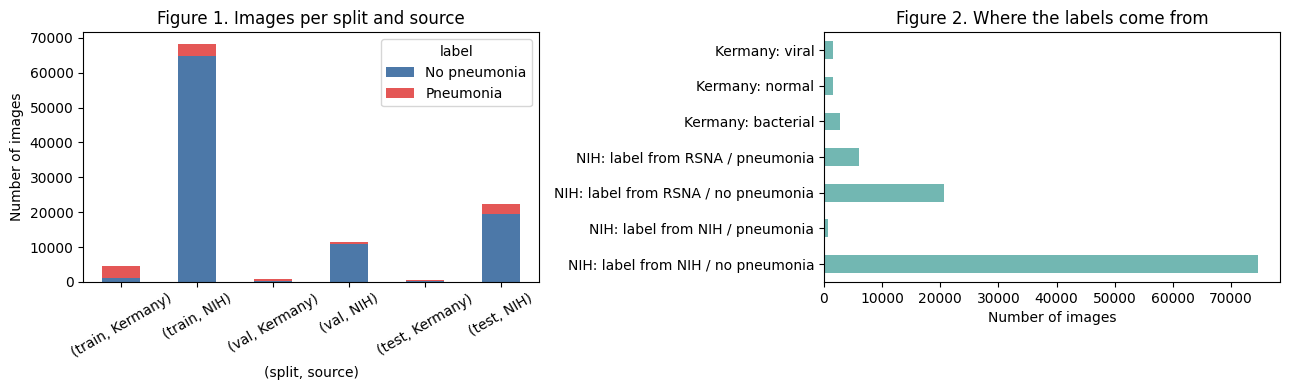

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts = manifest.groupby(["split", "source", "label"]).size().unstack("label", fill_value=0)
counts = counts.reindex(["train", "val", "test"], level="split")
counts.rename(columns={0: "No pneumonia", 1: "Pneumonia"}).plot.bar(stacked=True, ax=axes[0], color=["#4C78A8", "#E45756"])
axes[0].set_title("Figure 1. Images per split and source")
axes[0].set_xlabel("(split, source)")
axes[0].set_ylabel("Number of images")
axes[0].tick_params(axis="x", rotation=30)

sub = manifest[manifest.source == "Kermany"].subtype.value_counts()
nih_reason = manifest[manifest.source == "NIH"].groupby(["label_source", "label"]).size()
nih_reason.index = [f"{s} / {'pneumonia' if l else 'no pneumonia'}" for s, l in nih_reason.index]
pd.concat([nih_reason.rename(lambda s: "NIH: label from " + s), sub.rename(lambda s: "Kermany: " + s)]).plot.barh(
    ax=axes[1], color="#72B7B2")
axes[1].set_title("Figure 2. Where the labels come from")
axes[1].set_xlabel("Number of images")
plt.tight_layout()
plt.show()

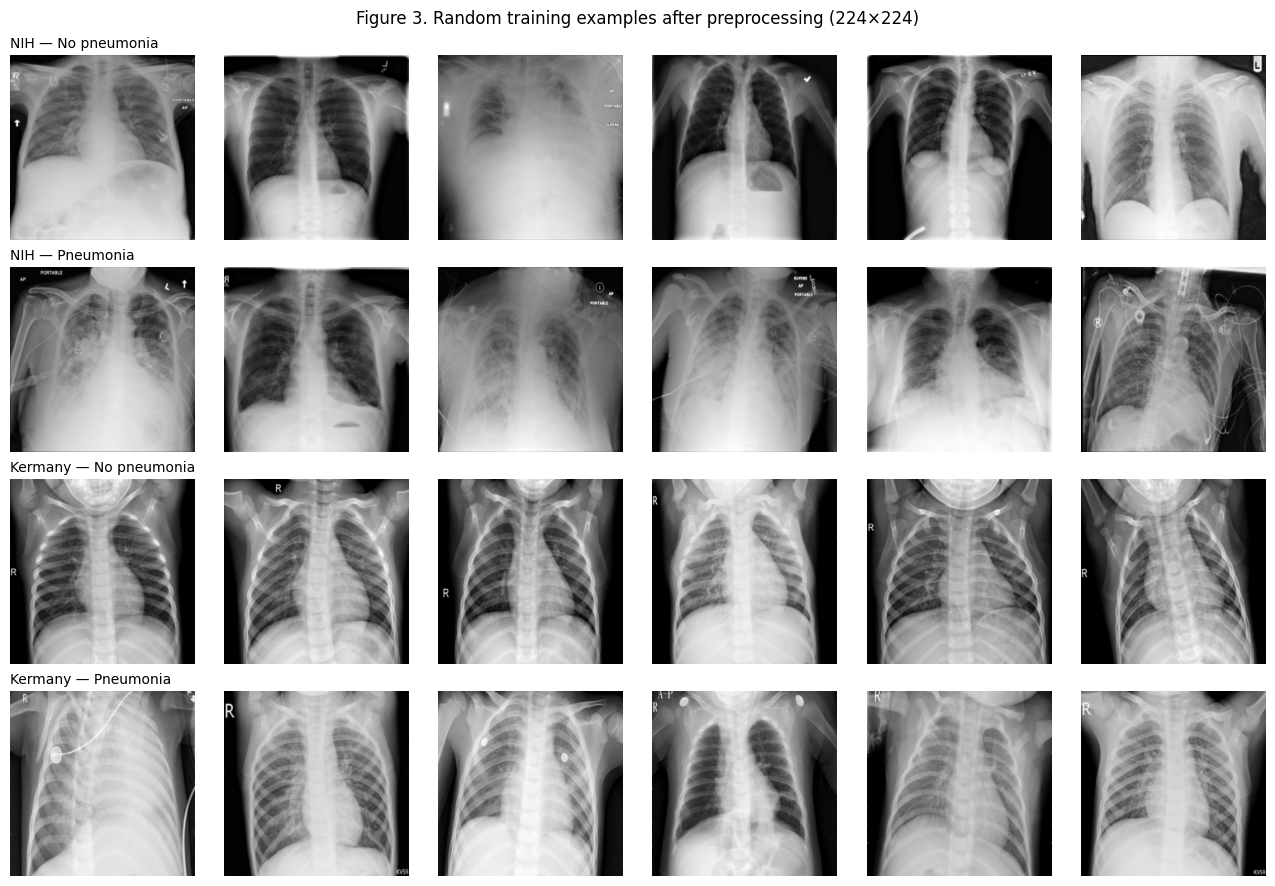

In [16]:
rng = np.random.default_rng(SEED)
groups = [("NIH", 0), ("NIH", 1), ("Kermany", 0), ("Kermany", 1)]
fig, axes = plt.subplots(len(groups), 6, figsize=(13, 9))
for row, (source, label) in enumerate(groups):
    idx = manifest[(manifest.source == source) & (manifest.label == label)].cache_idx.to_numpy()
    for col, i in enumerate(rng.choice(idx, size=min(6, len(idx)), replace=False)):
        axes[row, col].imshow(IMAGES[i], cmap="gray")
    for ax in axes[row]:
        ax.axis("off")
    axes[row, 0].set_title(f"{source} — {'Pneumonia' if label else 'No pneumonia'}", loc="left", fontsize=10)
fig.suptitle("Figure 3. Random training examples after preprocessing (224×224)")
plt.tight_layout()
plt.show()

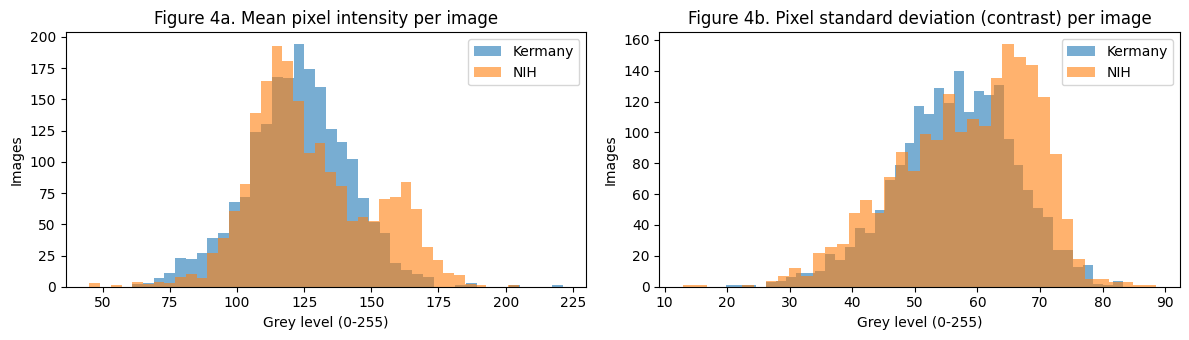

mean                                                    std        \
          count   mean   std   min    25%    50%    75%    max   count  mean   
source                                                                         
Kermany  2000.0  122.6  19.0  60.9  110.9  122.8  134.9  221.3  2000.0  56.5   
NIH      2000.0  127.5  22.6  45.0  111.8  122.6  142.8  204.8  2000.0  58.3   

                                             
          std   min   25%   50%   75%   max  
source                                       
Kermany   9.6  19.8  50.4  56.8  63.2  83.2  
NIH      10.9  12.9  50.9  59.8  66.9  88.6

In [17]:
# Domain shift check: adult (NIH) and paediatric (Kermany) images differ in brightness/contrast. A CNN could learn
# "which hospital" instead of "which disease" - we keep this in mind when reading the results.
sample = manifest.groupby("source").sample(n=min(2000, manifest.source.value_counts().min()), random_state=SEED)
stats = sample.assign(mean=[IMAGES[i].mean() for i in sample.cache_idx], std=[IMAGES[i].std() for i in sample.cache_idx])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for source, part in stats.groupby("source"):
    axes[0].hist(part["mean"], bins=40, alpha=0.6, label=source)
    axes[1].hist(part["std"], bins=40, alpha=0.6, label=source)
axes[0].set_title("Figure 4a. Mean pixel intensity per image")
axes[1].set_title("Figure 4b. Pixel standard deviation (contrast) per image")
for ax in axes:
    ax.set_xlabel("Grey level (0-255)")
    ax.set_ylabel("Images")
    ax.legend()
plt.tight_layout()
plt.show()
display(stats.groupby("source")[["mean", "std"]].describe().round(1))

## 7. Input pipeline, augmentation (D7) and class weights (D8)

`tf.data` reads batches from the memory-mapped cache, converts them to 3 channels and prefetches the next batch
while the GPU is busy. Augmentation is a Keras block that will be the first layer of the model, so it runs on the GPU
and only during training: rotation ±10°, shifts up to 10 %, zoom up to 10 %, brightness ±10 %.
**No vertical flips** — an upside-down chest is anatomically unrealistic.

In [18]:
AUTOTUNE = tf.data.AUTOTUNE
LABELS_BY_IDX = np.zeros(len(IMAGES), dtype=np.float32)
LABELS_BY_IDX[manifest.cache_idx.to_numpy()] = manifest.label.to_numpy()


def _read_batch(idx):
    idx = np.sort(idx)                      # sorted reads are faster on a memory map; order inside a batch is irrelevant
    return IMAGES[idx], LABELS_BY_IDX[idx]


def _to_model_input(images, labels):
    images = tf.ensure_shape(images, [None, IMG_SIZE, IMG_SIZE])
    images = tf.repeat(tf.cast(images, tf.float32)[..., None], 3, axis=-1)     # grayscale -> 3 channels, range 0..255
    return images, tf.ensure_shape(labels, [None])


def make_dataset(split, training=False, sources=None, batch_size=BATCH_SIZE):
    rows = manifest[manifest.split == split]
    if sources is not None:
        rows = rows[rows.source.isin(sources)]
    ds = tf.data.Dataset.from_tensor_slices(rows.cache_idx.to_numpy())
    if training:
        ds = ds.shuffle(len(rows), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size)
    ds = ds.map(lambda i: tf.numpy_function(_read_batch, [i], (tf.uint8, tf.float32)), num_parallel_calls=AUTOTUNE)
    return ds.map(_to_model_input, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)


train_ds = make_dataset("train", training=True)
val_ds = make_dataset("val")
test_nih_ds = make_dataset("test", sources=["NIH"])
test_kermany_ds = make_dataset("test", sources=["Kermany"])     # the 624-image benchmark from the proposal

x, y = next(iter(train_ds))
print("Batch:", x.shape, x.dtype, "| labels:", y.numpy()[:10], "| pixel range:", float(tf.reduce_min(x)), "-", float(tf.reduce_max(x)))

Batch: (32, 224, 224, 3) <dtype: 'float32'> | labels: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.] | pixel range: 0.0 - 255.0


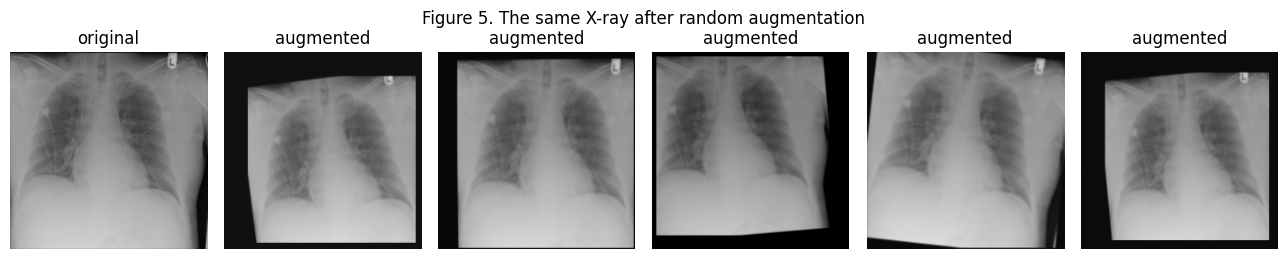

In [19]:
def make_augmentation():
    return tf.keras.Sequential([
        tf.keras.layers.RandomRotation(10 / 360, fill_mode="constant"),       # ±10°
        tf.keras.layers.RandomTranslation(0.10, 0.10, fill_mode="constant"),  # shifts up to 10 %
        tf.keras.layers.RandomZoom(0.10, fill_mode="constant"),               # zoom up to 10 %
        tf.keras.layers.RandomBrightness(0.10, value_range=(0, 255)),         # brightness ±10 %
    ], name="augmentation")


augmentation = make_augmentation()

example = x[:1]
fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
axes[0].imshow(example[0, ..., 0].numpy(), cmap="gray", vmin=0, vmax=255)
axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(augmentation(example, training=True)[0, ..., 0].numpy(), cmap="gray", vmin=0, vmax=255)
    ax.set_title("augmented")
for ax in axes:
    ax.axis("off")
fig.suptitle("Figure 5. The same X-ray after random augmentation")
plt.tight_layout()
plt.show()

In [20]:
# D8: "balanced" weights = n_samples / (n_classes * n_class_samples): the rare pneumonia class gets a larger weight in the loss.
train_labels = manifest.loc[manifest.split == "train", "label"].to_numpy()
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=train_labels)
CLASS_WEIGHT = {0: float(weights[0]), 1: float(weights[1])}
print(f"Training images: {len(train_labels):,} | pneumonia share: {train_labels.mean():.1%}")
print("Class weights:", {k: round(v, 3) for k, v in CLASS_WEIGHT.items()})

Training images: 72,676 | pneumonia share: 9.0%
Class weights: {0: 0.55, 1: 5.525}


## 8. Evaluation protocol (D10)

Every model is evaluated the same way on three sets:

* **val** — used to choose hyperparameters (never the test sets);
* **test NIH** — official patient-wise NIH test list (adults);
* **test Kermany** — official Kermany test folder, 624 children; the success targets of the proposal refer to this set.

Pneumonia is only ≈6 % of the training data, so **accuracy alone is misleading** (predicting "no pneumonia" for every
image is already ≈94 % accurate on NIH). We therefore report sensitivity (recall of pneumonia), specificity, precision,
F1, ROC-AUC and PR-AUC (average precision) next to accuracy.

In [21]:
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay)

ROW_IDX = manifest.cache_idx.to_numpy()                  # all images, in manifest order
assert np.all(np.diff(ROW_IDX) > 0)
Y_ALL = manifest.label.to_numpy()
EVAL_SETS = {
    "val": (manifest.split == "val").to_numpy(),
    "test NIH": ((manifest.split == "test") & (manifest.source == "NIH")).to_numpy(),
    "test Kermany": ((manifest.split == "test") & (manifest.source == "Kermany")).to_numpy(),
}
TRAIN_MASK = (manifest.split == "train").to_numpy()
RESULTS = []          # one row per (model, evaluation set); shared by baselines and CNNs


def ordered_dataset(batch_size=128):
    # All images in manifest order (no shuffling, no augmentation) - used for feature extraction and prediction.
    ds = tf.data.Dataset.from_tensor_slices(ROW_IDX).batch(batch_size)
    ds = ds.map(lambda i: tf.numpy_function(lambda j: IMAGES[j], [i], tf.uint8), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x: tf.repeat(tf.cast(tf.ensure_shape(x, [None, IMG_SIZE, IMG_SIZE]), tf.float32)[..., None], 3, -1),
                num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


def metrics(y_true, scores, threshold):
    y_pred = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "sensitivity": recall_score(y_true, y_pred, zero_division=0),
        "specificity": tn / (tn + fp) if tn + fp else np.nan,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, scores) if len(set(y_true)) > 1 else np.nan,
        "PR-AUC": average_precision_score(y_true, scores) if len(set(y_true)) > 1 else np.nan,
    }


def evaluate(name, scores, threshold):
    # `scores` covers every image in manifest order; higher = more likely pneumonia.
    # `threshold` is one number or a dict {evaluation set: threshold}.
    for set_name, mask in EVAL_SETS.items():
        if not mask.any():
            continue
        RESULTS[:] = [r for r in RESULTS if (r["model"], r["set"]) != (name, set_name)]   # re-running a cell replaces
        RESULTS.append({"model": name, "set": set_name, **metrics(Y_ALL[mask], scores[mask], threshold[set_name] if isinstance(threshold, dict) else threshold)})


def results_table(sets=("val", "test NIH", "test Kermany"), columns=("accuracy", "sensitivity", "specificity", "F1", "ROC-AUC")):
    df = pd.DataFrame(RESULTS)
    df = df[df.set.isin(sets)].pivot(index="model", columns="set", values=list(columns))
    df = df.reindex(columns=pd.MultiIndex.from_product([columns, sets]))
    return df.reindex(dict.fromkeys(r["model"] for r in RESULTS)).round(3)

## 9. Classical baselines (D11)

The baselines answer the question *"how much does deep learning add?"*. All of them use `class_weight="balanced"`
(D8) and pick the regularisation strength `C` on the validation ROC-AUC.

| # | Features | Classifier |
|---|---|---|
| 0 | none | majority class (shows why accuracy is misleading) |
| 1–2 | raw pixels: 224×224 averaged down to 56×56 = 3,136 values → standardised → PCA, 256 components | logistic regression, linear SVM |
| 3–4 | 2,048-d features of an ImageNet ResNet50 with **frozen** weights (no training on X-rays) | logistic regression, linear SVM |

Baselines 3–4 isolate the effect of *fine-tuning*: the CNN in section 10 uses the same backbone, but trains it.
Kernel (RBF) SVMs scale quadratically with the number of samples and are not practical for ~85k training images,
hence linear models.

In [22]:
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((TRAIN_MASK.sum(), 1)), Y_ALL[TRAIN_MASK])
evaluate("0 Majority class", dummy.predict(np.zeros((len(Y_ALL), 1))).astype(float), threshold=0.5)
display(results_table(columns=("accuracy", "sensitivity", "specificity", "F1")).loc[["0 Majority class"]])

accuracy                       sensitivity           \
                      val test NIH test Kermany         val test NIH   
model                                                                  
0 Majority class    0.909    0.874        0.375         0.0      0.0   

                              specificity                         F1           \
                 test Kermany         val test NIH test Kermany  val test NIH   
model                                                                           
0 Majority class          0.0         1.0      1.0          1.0  0.0      0.0   

                               
                 test Kermany  
model                          
0 Majority class          0.0

In [23]:
def fit_and_select(name, make_clf, Cs, X):
    # Fit one classifier per C on train, keep the best by validation ROC-AUC, evaluate it on all sets.
    Xtr, ytr = X[TRAIN_MASK], Y_ALL[TRAIN_MASK]
    val = EVAL_SETS["val"]
    best, log = None, []
    for C in Cs:
        t0 = time.time()
        clf = make_clf(C).fit(Xtr, ytr)
        auc = roc_auc_score(Y_ALL[val], clf.decision_function(X[val]))
        log.append({"C": C, "val ROC-AUC": round(auc, 4), "fit time, s": round(time.time() - t0, 1)})
        if best is None or auc > best[0]:
            best = (auc, C, clf)
    print(f"{name}: best C = {best[1]}")
    display(pd.DataFrame(log).set_index("C").T)
    scores = best[2].decision_function(X)          # signed distance / logit: 0 is the decision boundary
    evaluate(name, scores, threshold=0.0)
    return best[2], scores


make_logreg = lambda C: LogisticRegression(C=C, class_weight="balanced", max_iter=3000)
make_svm = lambda C: LinearSVC(C=C, class_weight="balanced", max_iter=5000)
BASELINE_SCORES = {}

### 9.1 Pixel features

In [24]:
PIX = 56
assert IMG_SIZE % PIX == 0
factor = IMG_SIZE // PIX
X_pix = np.empty((len(ROW_IDX), PIX * PIX), dtype=np.float32)
for s in tqdm(range(0, len(ROW_IDX), 2048), desc="Pixel features"):
    block = IMAGES[ROW_IDX[s:s + 2048]].astype(np.float32) / 255.0
    X_pix[s:s + 2048] = block.reshape(-1, PIX, factor, PIX, factor).mean(axis=(2, 4)).reshape(len(block), -1)

n_comp = min(256, TRAIN_MASK.sum() - 1, X_pix.shape[1])
reducer = make_pipeline(StandardScaler(), PCA(n_components=n_comp, svd_solver="randomized", random_state=SEED))
reducer.fit(X_pix[TRAIN_MASK])                      # fitted on training images only (no information from val/test)
Z_pix = reducer.transform(X_pix).astype(np.float32)
print(f"{X_pix.shape[1]} pixels -> {n_comp} PCA components, explained variance "
      f"{reducer[-1].explained_variance_ratio_.sum():.1%}")

_, BASELINE_SCORES["1 Pixels + LogReg"] = fit_and_select("1 Pixels + LogReg", make_logreg, [0.001, 0.01, 0.1, 1.0], Z_pix)
_, BASELINE_SCORES["2 Pixels + Linear SVM"] = fit_and_select("2 Pixels + Linear SVM", make_svm, [0.0001, 0.001, 0.01, 0.1], Z_pix)

# Free RAM before the next block: liblinear (LinearSVC) makes a float64 + sparse copy of ~100k x 2048 features
# (~4 GB), which does not fit into a 12.7 GB Colab runtime if the raw pixel matrix is still held.
import gc
del X_pix
gc.collect()

Pixel features:   0%|          | 0/53 [00:00<?, ?it/s]

3136 pixels -> 256 PCA components, explained variance 97.1%
1 Pixels + LogReg: best C = 0.001


C,0.001,0.010,0.100,1.000
val ROC-AUC,0.8853,0.8846,0.8845,0.8845
"fit time, s",5.6000,6.6000,5.9000,6.1000


2 Pixels + Linear SVM: best C = 0.0001


C,0.0001,0.0010,0.0100,0.1000
val ROC-AUC,0.8864,0.8859,0.8858,0.8858
"fit time, s",9.1000,10.7000,11.1000,11.0000


59602

### 9.2 Frozen ResNet50 features

In [25]:
FEAT_FILE = CACHE_DIR / f"resnet50_imagenet_avgpool_{IMG_SIZE}.npy"
if FEAT_FILE.exists() and np.load(FEAT_FILE, mmap_mode="r").shape[0] == len(ROW_IDX):
    X_cnn = np.load(FEAT_FILE)
    print("Loaded cached features:", X_cnn.shape)
else:
    if not tf.config.list_physical_devices("GPU"):
        print("WARNING: no GPU - extracting features for ~100k images on a CPU takes hours.")
    feature_extractor = tf.keras.Sequential([
        tf.keras.Input((IMG_SIZE, IMG_SIZE, 3)),
        tf.keras.layers.Lambda(tf.keras.applications.resnet50.preprocess_input),
        tf.keras.applications.ResNet50(weights="imagenet", include_top=False, pooling="avg"),
    ], name="frozen_resnet50")
    t0 = time.time()
    X_cnn = feature_extractor.predict(ordered_dataset(), verbose=1).astype(np.float32)
    np.save(FEAT_FILE, X_cnn)
    print(f"Features {X_cnn.shape} extracted in {(time.time() - t0) / 60:.1f} min")

scaler = StandardScaler().fit(X_cnn[TRAIN_MASK])
Z_cnn = scaler.transform(X_cnn).astype(np.float32)
del X_cnn                                           # only the standardised copy is needed from here on
feature_extractor = None
gc.collect()
_, BASELINE_SCORES["3 ResNet50 features + LogReg"] = fit_and_select(
    "3 ResNet50 features + LogReg", make_logreg, [0.0001, 0.001, 0.01, 0.1], Z_cnn)
_, BASELINE_SCORES["4 ResNet50 features + Linear SVM"] = fit_and_select(
    "4 ResNet50 features + Linear SVM", make_svm, [0.00001, 0.0001, 0.001, 0.01], Z_cnn)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
843/843 ━━━━━━━━━━━━━━━━━━━━ 337s 389ms/step
Features (107858, 2048) extracted in 5.6 min
3 ResNet50 features + LogReg: best C = 0.0001


C,0.0001,0.0010,0.0100,0.1000
val ROC-AUC,0.9298,0.9265,0.9177,0.9143
"fit time, s",6.7000,13.7000,25.1000,30.9000


4 ResNet50 features + Linear SVM: best C = 1e-05


C,0.00001,0.00010,0.00100,0.01000
val ROC-AUC,0.9289,0.9254,0.9179,0.9152
"fit time, s",38.5000,76.3000,97.4000,145.2000


### 9.3 Baseline results

Table 1. Baselines on the validation and both test sets (threshold = default decision boundary)


accuracy                       sensitivity  \
                                      val test NIH test Kermany         val   
model                                                                         
0 Majority class                    0.909    0.874        0.375       0.000   
1 Pixels + LogReg                   0.839    0.682        0.691       0.776   
2 Pixels + Linear SVM               0.838    0.679        0.689       0.782   
3 ResNet50 features + LogReg        0.864    0.671        0.740       0.832   
4 ResNet50 features + Linear SVM    0.818    0.597        0.705       0.881   

                                                       specificity           \
                                 test NIH test Kermany         val test NIH   
model                                                                         
0 Majority class                    0.000          0.0       1.000    1.000   
1 Pixels + LogReg                   0.660          1.0       0.845    0.685   
2 Pixels + Linear SVM               0.662          1.0       0.844    0.682   
3 ResNet50 features + LogReg        0.789          1.0       0.867    0.654   
4 ResNet50 features + Linear SVM    0.856          1.0       0.811    0.560   

                                                  F1                        \
                                 test Kermany    val test NIH test Kermany   
model                                                                        
0 Majority class                        1.000  0.000    0.000        0.000   
1 Pixels + LogReg                       0.175  0.467    0.344        0.802   
2 Pixels + Linear SVM                   0.171  0.468    0.343        0.801   
3 ResNet50 features + LogReg            0.308  0.527    0.377        0.828   
4 ResNet50 features + Linear SVM        0.214  0.468    0.349        0.809   

                                 ROC-AUC                        
                                     val test NIH test Kermany  
model                                                           
0 Majority class                   0.500    0.500        0.500  
1 Pixels + LogReg                  0.885    0.724        0.827  
2 Pixels + Linear SVM              0.886    0.726        0.836  
3 ResNet50 features + LogReg       0.930    0.783        0.916  
4 ResNet50 features + Linear SVM   0.929    0.783        0.913

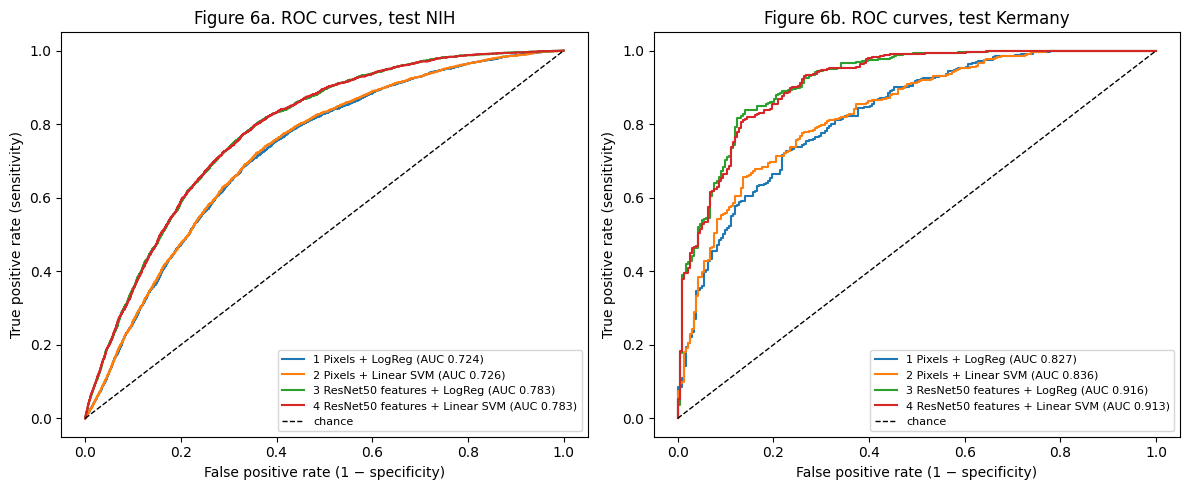

In [26]:
print("Table 1. Baselines on the validation and both test sets (threshold = default decision boundary)")
display(results_table())
pd.DataFrame(RESULTS).to_csv(WORK_DIR / "results.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, set_name in zip(axes, ["test NIH", "test Kermany"]):
    mask = EVAL_SETS[set_name]
    for name, scores in BASELINE_SCORES.items():
        fpr, tpr, _ = roc_curve(Y_ALL[mask], scores[mask])
        ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(Y_ALL[mask], scores[mask]):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="chance")
    ax.set_title(f"Figure 6{'ab'[set_name == 'test Kermany']}. ROC curves, {set_name}")
    ax.set_xlabel("False positive rate (1 − specificity)")
    ax.set_ylabel("True positive rate (sensitivity)")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

Best baseline by validation ROC-AUC: 3 ResNet50 features + LogReg


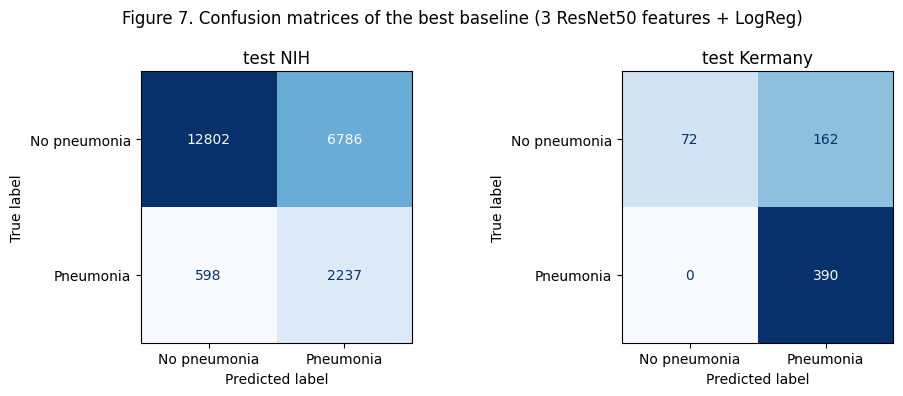

In [27]:
val_auc = {r["model"]: r["ROC-AUC"] for r in RESULTS if r["set"] == "val" and r["model"] in BASELINE_SCORES}
BEST_BASELINE = max(val_auc, key=val_auc.get)
print("Best baseline by validation ROC-AUC:", BEST_BASELINE)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, set_name in zip(axes, ["test NIH", "test Kermany"]):
    mask = EVAL_SETS[set_name]
    ConfusionMatrixDisplay.from_predictions(
        Y_ALL[mask], (BASELINE_SCORES[BEST_BASELINE][mask] >= 0).astype(int),
        display_labels=["No pneumonia", "Pneumonia"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(set_name)
fig.suptitle(f"Figure 7. Confusion matrices of the best baseline ({BEST_BASELINE})")
plt.tight_layout()
plt.show()

## 10. CNN with transfer learning (D5, D6, D9)

**Architecture.**
`X-ray 224×224×3 → augmentation (training only) → ImageNet preprocessing → ResNet50 backbone (ImageNet weights)
→ global average pooling → dropout 0.3 → dense(1, sigmoid) = P(pneumonia)`

**Training in two stages** (the dataset is large, but X-rays look very different from ImageNet photos, so we first
fit the new head and only then adapt the deepest, most task-specific features):

| Stage | Trainable | Optimiser | Epochs (max) |
|---|---|---|---|
| 1 | only the new head (2,049 weights) | Adam, lr = 1e-3 | 3 |
| 2 | + last convolutional block `conv5` (BatchNorm layers stay frozen) | Adam, lr = 1e-5 | 7 |

Loss: binary cross-entropy with the class weights from section 7 (D8). Batch size 32.

**Callbacks (D9):** `ModelCheckpoint` keeps the epoch with the best validation ROC-AUC (`.keras` file, N8),
`EarlyStopping` stops when validation loss has not improved for 3 epochs, `ReduceLROnPlateau` divides the learning
rate by 5 after 2 epochs without improvement, `CSVLogger` stores the learning curves.

Other backbones (N5) can be compared under identical conditions by adding them to `BACKBONES_TO_TRAIN`.

In [28]:
BACKBONES_TO_TRAIN = ["resnet50"]          # N5: e.g. ["resnet50", "vgg16", "efficientnetb0"] (~1 h each on a T4)
STAGE1_EPOCHS = int(os.environ.get("PNEUMODETECT_STAGE1_EPOCHS", 3))
STAGE2_EPOCHS = int(os.environ.get("PNEUMODETECT_STAGE2_EPOCHS", 7))
STAGE1_LR, STAGE2_LR = 1e-3, 1e-5
DROPOUT = 0.3
TARGET_SENSITIVITY = 0.95                  # N6: a missed pneumonia costs more than a false alarm
REUSE_CHECKPOINTS = True                   # skip training if a finished checkpoint for this backbone already exists

# name: (constructor, input preprocessing, prefixes of the last convolutional block)
BACKBONES = {
    "resnet50": (tf.keras.applications.ResNet50, "caffe", ("conv5_",)),
    "vgg16": (tf.keras.applications.VGG16, "caffe", ("block5_",)),
    "efficientnetb0": (tf.keras.applications.EfficientNetB0, "built-in", ("block7", "top_")),
}

# Mixed precision roughly doubles training speed on T4/V100/A100 GPUs (compute capability >= 7.0).
gpus = tf.config.list_physical_devices("GPU")
capability = tf.config.experimental.get_device_details(gpus[0]).get("compute_capability", (0, 0)) if gpus else (0, 0)
if capability >= (7, 0):
    tf.keras.mixed_precision.set_global_policy("mixed_float16")
print("Precision policy:", tf.keras.mixed_precision.global_policy().name)

# Keras expects labels shaped like the model output: (batch, 1).
cnn_train_ds = train_ds.map(lambda x, y: (x, y[:, None]))
cnn_val_ds = val_ds.map(lambda x, y: (x, y[:, None]))

Precision policy: mixed_float16


In [29]:
def build_model(name):
    constructor, preprocessing, last_block = BACKBONES[name]
    inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3), name="xray")
    x = make_augmentation()(inputs)                                   # D7, active only during training
    if preprocessing == "caffe":
        # ImageNet "caffe" preprocessing = subtract the per-channel mean (the RGB->BGR swap does nothing for
        # grayscale images whose three channels are identical).
        x = tf.keras.layers.Normalization(mean=[103.939, 116.779, 123.68], variance=[1.0, 1.0, 1.0],
                                          name="imagenet_preprocessing")(x)
    base = constructor(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False                                            # stage 1: backbone frozen
    x = base(x, training=False)                                       # BatchNorm always in inference mode
    x = tf.keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = tf.keras.layers.Dropout(DROPOUT, name="dropout")(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid", dtype="float32", name="p_pneumonia")(x)   # D5
    return tf.keras.Model(inputs, outputs, name=f"pneumodetect_{name}"), base, last_block


def compile_model(model, lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"), tf.keras.metrics.AUC(name="auc"),
                           tf.keras.metrics.Recall(name="recall"), tf.keras.metrics.Precision(name="precision")])


def unfreeze_last_block(base, prefixes):
    base.trainable = True
    for layer in base.layers:
        layer.trainable = (layer.name.startswith(prefixes)
                           and not isinstance(layer, tf.keras.layers.BatchNormalization))


def count_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))


model_preview, _, _ = build_model("resnet50")
model_preview.summary(expand_nested=False)
del model_preview

Model: "pneumodetect_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xray (InputLayer)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imagenet_preprocessing          │ (None, 224, 224, 3)    │             0 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_pneumonia (Dense)             │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [30]:
def callbacks(name, stage, best_auc=None):
    return [
        tf.keras.callbacks.ModelCheckpoint(WORK_DIR / f"pneumodetect_{name}_best.keras", monitor="val_auc", mode="max",
                                           save_best_only=True, initial_value_threshold=best_auc, verbose=1),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7, verbose=1),
        tf.keras.callbacks.CSVLogger(WORK_DIR / f"history_{name}_stage{stage}.csv"),
    ]


def train_backbone(name):
    ckpt = WORK_DIR / f"pneumodetect_{name}_best.keras"
    logs = [WORK_DIR / f"history_{name}_stage{s}.csv" for s in (1, 2)]
    if REUSE_CHECKPOINTS and ckpt.exists() and all(p.exists() for p in logs):
        print(f"{name}: reusing {ckpt.name}")
    else:
        model, base, last_block = build_model(name)
        compile_model(model, STAGE1_LR)
        print(f"Stage 1 - head only: {count_trainable(model):,} trainable weights")
        h1 = model.fit(cnn_train_ds, validation_data=cnn_val_ds, epochs=STAGE1_EPOCHS, class_weight=CLASS_WEIGHT,
                       shuffle=False, callbacks=callbacks(name, 1), verbose=2)
        unfreeze_last_block(base, last_block)
        compile_model(model, STAGE2_LR)                       # recompile so the new trainable flags take effect
        print(f"Stage 2 - fine-tuning the last block: {count_trainable(model):,} trainable weights")
        model.fit(cnn_train_ds, validation_data=cnn_val_ds, epochs=STAGE2_EPOCHS, class_weight=CLASS_WEIGHT,
                  shuffle=False, callbacks=callbacks(name, 2, best_auc=max(h1.history["val_auc"])), verbose=2)
    history = pd.concat([pd.read_csv(p).assign(stage=s) for s, p in enumerate(logs, start=1)], ignore_index=True)
    best = tf.keras.models.load_model(ckpt)                   # N8: the saved file is what we evaluate
    return best, history


CNN = {}
for name in BACKBONES_TO_TRAIN:
    t0 = time.time()
    model, history = train_backbone(name)
    CNN[name] = {"model": model, "history": history}
    print(f"{name}: done in {(time.time() - t0) / 60:.1f} min, best checkpoint "
          f"{WORK_DIR / f'pneumodetect_{name}_best.keras'} "
          f"({(WORK_DIR / f'pneumodetect_{name}_best.keras').stat().st_size / 1e6:.0f} MB)")

Stage 1 - head only: 2,049 trainable weights
Epoch 1/3

Epoch 1: val_auc improved from None to 0.91707, saving model to /kaggle/working/pneumodetect_resnet50_best.keras

Epoch 1: finished saving model to /kaggle/working/pneumodetect_resnet50_best.keras
2272/2272 - 264s - 116ms/step - accuracy: 0.8115 - auc: 0.8822 - loss: 0.4354 - precision: 0.2970 - recall: 0.7919 - val_accuracy: 0.8890 - val_auc: 0.9171 - val_loss: 0.2738 - val_precision: 0.4374 - val_recall: 0.7613 - learning_rate: 0.0010
Epoch 2/3

Epoch 2: val_auc improved from 0.91707 to 0.91909, saving model to /kaggle/working/pneumodetect_resnet50_best.keras

Epoch 2: finished saving model to /kaggle/working/pneumodetect_resnet50_best.keras
2272/2272 - 247s - 109ms/step - accuracy: 0.8272 - auc: 0.8966 - loss: 0.4077 - precision: 0.3197 - recall: 0.8061 - val_accuracy: 0.8612 - val_auc: 0.9191 - val_loss: 0.3143 - val_precision: 0.3773 - val_recall: 0.8038 - learning_rate: 0.0010
Epoch 3/3

Epoch 3: val_auc improved from 0.9190

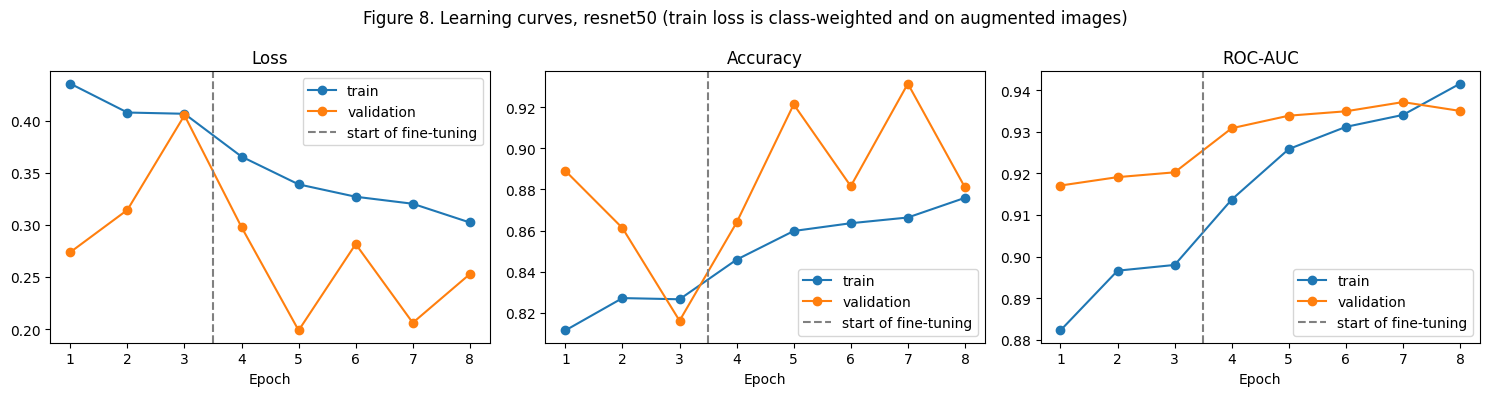

In [31]:
for i, (name, run) in enumerate(CNN.items()):
    h = run["history"]
    epochs = np.arange(1, len(h) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, metric, title in zip(axes, ["loss", "accuracy", "auc"], ["Loss", "Accuracy", "ROC-AUC"]):
        ax.plot(epochs, h[metric], "o-", label="train")
        ax.plot(epochs, h["val_" + metric], "o-", label="validation")
        ax.axvline((h.stage == 1).sum() + 0.5, color="gray", ls="--", label="start of fine-tuning")
        ax.set_xlabel("Epoch")
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.set_title(title)
        ax.legend()
    fig.suptitle(f"Figure {8 + i}. Learning curves, {name} (train loss is class-weighted and on augmented images)")
    plt.tight_layout()
    plt.show()

### 10.1 Evaluation and decision threshold (D10, N6, N7)

The sigmoid output is a probability, but 0.5 is not automatically the right cut-off: with 6 % positives the model
leans towards "no pneumonia". Following the proposal (missing pneumonia is worse than a false alarm), we also pick the
**highest threshold that reaches 95 % sensitivity on the validation set**. Because adult (NIH) and paediatric
(Kermany) images behave differently, the threshold is chosen on the validation images *of the same source* as the
test set — a per-site calibration that uses no test data.

In [32]:
def threshold_for_sensitivity(y, scores, target=TARGET_SENSITIVITY):
    fpr, tpr, thr = roc_curve(y, scores)
    return float(min(thr[np.argmax(tpr >= target)], 1.0))   # first (= highest) threshold reaching the target


VAL_BY_SOURCE = {s: EVAL_SETS["val"] & (manifest.source == s).to_numpy() for s in ("NIH", "Kermany")}

for name, run in CNN.items():
    t0 = time.time()
    run["scores"] = run["model"].predict(ordered_dataset(), verbose=0).ravel().astype(np.float64)
    print(f"{name}: predicted {len(ROW_IDX):,} images in {time.time() - t0:.0f} s")
    run["thresholds"] = {
        "val": threshold_for_sensitivity(Y_ALL[EVAL_SETS["val"]], run["scores"][EVAL_SETS["val"]]),
        "test NIH": threshold_for_sensitivity(Y_ALL[VAL_BY_SOURCE["NIH"]], run["scores"][VAL_BY_SOURCE["NIH"]]),
        "test Kermany": threshold_for_sensitivity(Y_ALL[VAL_BY_SOURCE["Kermany"]], run["scores"][VAL_BY_SOURCE["Kermany"]]),
    }
    evaluate(f"5 {name} fine-tuned (t = 0.5)", run["scores"], 0.5)
    evaluate(f"6 {name} fine-tuned (val-tuned t)", run["scores"], run["thresholds"])
    print("  val-tuned thresholds:", {k: round(v, 3) for k, v in run["thresholds"].items()})

    uncertain = (run["scores"] >= 0.4) & (run["scores"] <= 0.6)                # N7: "low confidence" flag
    print(f"  predictions flagged as uncertain (0.4-0.6): "
          + ", ".join(f"{s} {uncertain[m].mean():.1%}" for s, m in EVAL_SETS.items()))

print("\nTable 2. All models on the validation and both test sets")
display(results_table())
pd.DataFrame(RESULTS).to_csv(WORK_DIR / "results.csv", index=False)

resnet50: predicted 107,858 images in 293 s
  val-tuned thresholds: {'val': 0.127, 'test NIH': 0.077, 'test Kermany': 0.84}
  predictions flagged as uncertain (0.4-0.6): val 7.3%, test NIH 16.9%, test Kermany 5.0%

Table 2. All models on the validation and both test sets


accuracy                        \
                                         val test NIH test Kermany   
model                                                                
0 Majority class                       0.909    0.874        0.375   
1 Pixels + LogReg                      0.839    0.682        0.691   
2 Pixels + Linear SVM                  0.838    0.679        0.689   
3 ResNet50 features + LogReg           0.864    0.671        0.740   
4 ResNet50 features + Linear SVM       0.818    0.597        0.705   
5 resnet50 fine-tuned (t = 0.5)        0.931    0.801        0.812   
6 resnet50 fine-tuned (val-tuned t)    0.691    0.335        0.873   

                                    sensitivity                        \
                                            val test NIH test Kermany   
model                                                                   
0 Majority class                          0.000    0.000        0.000   
1 Pixels + LogReg                         0.776    0.660        1.000   
2 Pixels + Linear SVM                     0.782    0.662        1.000   
3 ResNet50 features + LogReg              0.832    0.789        1.000   
4 ResNet50 features + Linear SVM          0.881    0.856        1.000   
5 resnet50 fine-tuned (t = 0.5)           0.712    0.558        0.997   
6 resnet50 fine-tuned (val-tuned t)       0.950    0.982        0.977   

                                    specificity                           F1  \
                                            val test NIH test Kermany    val   
model                                                                          
0 Majority class                          1.000    1.000        1.000  0.000   
1 Pixels + LogReg                         0.845    0.685        0.175  0.467   
2 Pixels + Linear SVM                     0.844    0.682        0.171  0.468   
3 ResNet50 features + LogReg              0.867    0.654        0.308  0.527   
4 ResNet50 features + Linear SVM          0.811    0.560        0.214  0.468   
5 resnet50 fine-tuned (t = 0.5)           0.953    0.837        0.504  0.654   
6 resnet50 fine-tuned (val-tuned t)       0.665    0.241        0.701  0.359   

                                                          ROC-AUC           \
                                    test NIH test Kermany     val test NIH   
model                                                                        
0 Majority class                       0.000        0.000   0.500    0.500   
1 Pixels + LogReg                      0.344        0.802   0.885    0.724   
2 Pixels + Linear SVM                  0.343        0.801   0.886    0.726   
3 ResNet50 features + LogReg           0.377        0.828   0.930    0.783   
4 ResNet50 features + Linear SVM       0.349        0.809   0.929    0.783   
5 resnet50 fine-tuned (t = 0.5)        0.415        0.869   0.937    0.802   
6 resnet50 fine-tuned (val-tuned t)    0.272        0.906   0.937    0.802   

                                                  
                                    test Kermany  
model                                             
0 Majority class                           0.500  
1 Pixels + LogReg                          0.827  
2 Pixels + Linear SVM                      0.836  
3 ResNet50 features + LogReg               0.916  
4 ResNet50 features + Linear SVM           0.913  
5 resnet50 fine-tuned (t = 0.5)            0.944  
6 resnet50 fine-tuned (val-tuned t)        0.944

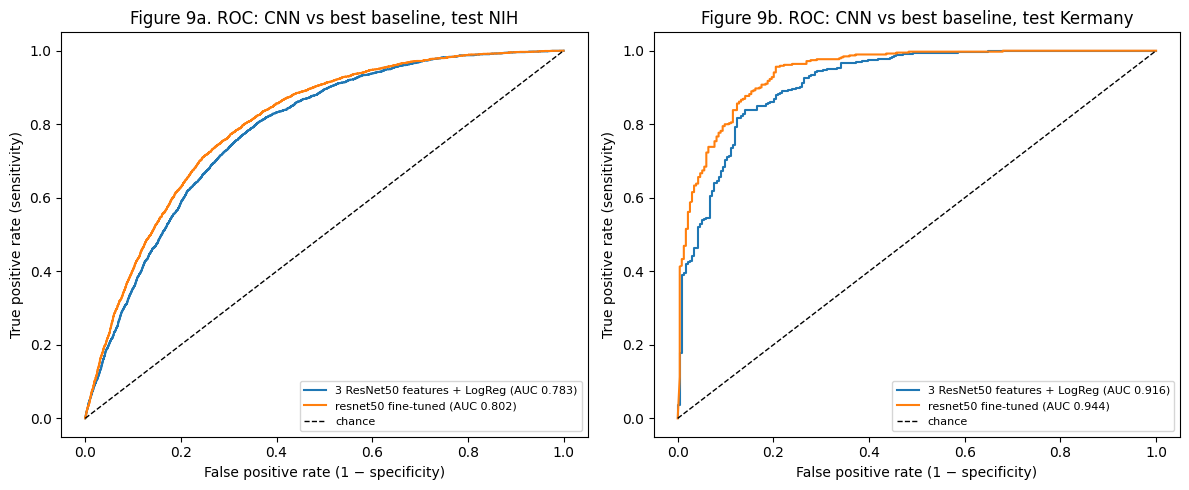

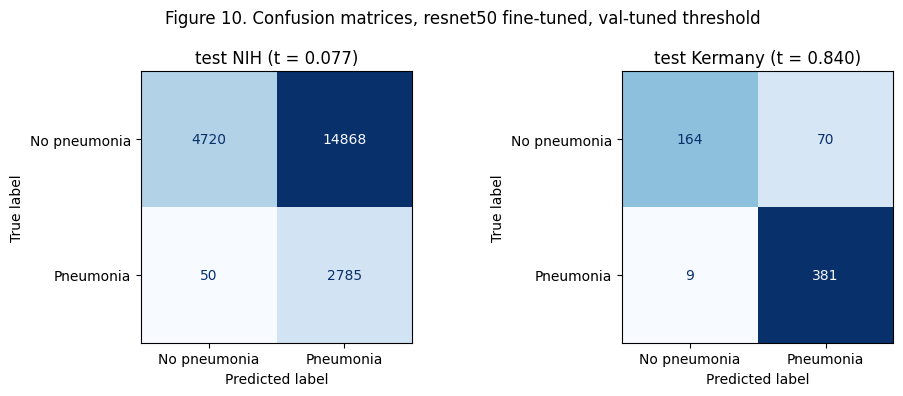

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
curves = {BEST_BASELINE: BASELINE_SCORES[BEST_BASELINE], **{f"{n} fine-tuned": r["scores"] for n, r in CNN.items()}}
for ax, set_name in zip(axes, ["test NIH", "test Kermany"]):
    mask = EVAL_SETS[set_name]
    for label, scores in curves.items():
        fpr, tpr, _ = roc_curve(Y_ALL[mask], scores[mask])
        ax.plot(fpr, tpr, label=f"{label} (AUC {roc_auc_score(Y_ALL[mask], scores[mask]):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="chance")
    ax.set_title(f"Figure {8 + len(CNN)}{'ab'[set_name == 'test Kermany']}. ROC: CNN vs best baseline, {set_name}")
    ax.set_xlabel("False positive rate (1 − specificity)")
    ax.set_ylabel("True positive rate (sensitivity)")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

MAIN = BACKBONES_TO_TRAIN[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, set_name in zip(axes, ["test NIH", "test Kermany"]):
    mask = EVAL_SETS[set_name]
    t = CNN[MAIN]["thresholds"][set_name]
    ConfusionMatrixDisplay.from_predictions(Y_ALL[mask], (CNN[MAIN]["scores"][mask] >= t).astype(int),
                                            display_labels=["No pneumonia", "Pneumonia"], cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(f"{set_name} (t = {t:.3f})")
fig.suptitle(f"Figure {9 + len(CNN)}. Confusion matrices, {MAIN} fine-tuned, val-tuned threshold")
plt.tight_layout()
plt.show()

### 10.2 Success criteria from the proposal (section 1.4)

Targets refer to the held-out Kermany test set (624 images). The CNN-vs-baseline comparison uses the default decision
rule of both models (t = 0.5 for the CNN, the SVM/LogReg boundary for the baseline), so neither side gets a tuned threshold.

In [34]:
def res(model, set_name, metric):
    return next(r[metric] for r in RESULTS if r["model"] == model and r["set"] == set_name)


tuned, default = f"6 {MAIN} fine-tuned (val-tuned t)", f"5 {MAIN} fine-tuned (t = 0.5)"
val_k = metrics(Y_ALL[VAL_BY_SOURCE["Kermany"]], CNN[MAIN]["scores"][VAL_BY_SOURCE["Kermany"]],
                CNN[MAIN]["thresholds"]["test Kermany"])

sample = next(iter(test_kermany_ds))[0][:1]
CNN[MAIN]["model"](sample, training=False)                     # warm-up
t0 = time.perf_counter()
for _ in range(20):
    CNN[MAIN]["model"](sample, training=False)
latency = (time.perf_counter() - t0) / 20

rows = [
    ("Test accuracy", "≥ 0.88", res(tuned, "test Kermany", "accuracy"), lambda v: v >= 0.88),
    ("Test sensitivity (recall of pneumonia)", "≥ 0.95", res(tuned, "test Kermany", "sensitivity"), lambda v: v >= 0.95),
    ("Test specificity", "≥ 0.80", res(tuned, "test Kermany", "specificity"), lambda v: v >= 0.80),
    ("Test F1", "≥ 0.90", res(tuned, "test Kermany", "F1"), lambda v: v >= 0.90),
    ("Test ROC-AUC", "≥ 0.95", res(tuned, "test Kermany", "ROC-AUC"), lambda v: v >= 0.95),
    ("Accuracy gain over best baseline (Kermany test)", "≥ +0.05",
     res(default, "test Kermany", "accuracy") - res(BEST_BASELINE, "test Kermany", "accuracy"), lambda v: v >= 0.05),
    ("F1 gain over best baseline (Kermany test)", "≥ +0.05",
     res(default, "test Kermany", "F1") - res(BEST_BASELINE, "test Kermany", "F1"), lambda v: v >= 0.05),
    ("Accuracy gain over best baseline (NIH test)", "≥ +0.05",
     res(default, "test NIH", "accuracy") - res(BEST_BASELINE, "test NIH", "accuracy"), lambda v: v >= 0.05),
    ("F1 gain over best baseline (NIH test)", "≥ +0.05",
     res(default, "test NIH", "F1") - res(BEST_BASELINE, "test NIH", "F1"), lambda v: v >= 0.05),
    ("Validation → test accuracy drop (Kermany)", "≤ 0.10 (reported)",
     val_k["accuracy"] - res(tuned, "test Kermany", "accuracy"), lambda v: v <= 0.10),
    ("Prediction time for one image, s", "< 2", latency, lambda v: v < 2),
]
criteria = pd.DataFrame([(c, t, round(v, 3), "yes" if ok(v) else "no") for c, t, v, ok in rows],
                        columns=["Criterion", "Target", "Result", "Met"])
print(f"Table 3. Proposal success criteria - {MAIN}, Kermany thresholds tuned on Kermany validation images")
display(criteria)
criteria.to_csv(WORK_DIR / "success_criteria.csv", index=False)

Table 3. Proposal success criteria - resnet50, Kermany thresholds tuned on Kermany validation images


,Criterion,Target,Result,Met
0,Test accuracy,≥ 0.88,0.873,no
1,Test sensitivity (recall of pneumonia),≥ 0.95,0.977,yes
2,Test specificity,≥ 0.80,0.701,no
3,Test F1,≥ 0.90,0.906,yes
4,Test ROC-AUC,≥ 0.95,0.944,no
5,Accuracy gain over best baseline (Kermany test),≥ +0.05,0.072,yes
6,F1 gain over best baseline (Kermany test),≥ +0.05,0.041,no
7,Accuracy gain over best baseline (NIH test),≥ +0.05,0.131,yes
8,F1 gain over best baseline (NIH test),≥ +0.05,0.038,no
9,Validation → test accuracy drop (Kermany),≤ 0.10 (reported),0.090,yes


## 11. Explaining predictions with Grad-CAM (N2)

Grad-CAM (Selvaraju et al., 2017) shows *where* the CNN looked. It takes the last convolutional feature map of the
backbone (7×7×2048 for ResNet50), weights every channel by the average gradient of the pneumonia *score* (the logit before the sigmoid, as in the
original paper) with respect to it, keeps the positive part and upsamples the 7×7 map to the image size.
Using the logit matters: for a confident prediction (P ≈ 1.00) the sigmoid is saturated and the gradient of the
probability is numerically zero, which would give an empty map.

Besides looking at examples, we check the maps **objectively**: for NIH test images with an RSNA *Lung Opacity* label,
radiologists drew bounding boxes around the opacity. We count how often the hottest point of the Grad-CAM map falls
inside a box (*pointing game*) and compare it with chance (the share of the image covered by the boxes).

In [35]:
def split_model(model):
    # The model is a chain: input -> augmentation -> preprocessing -> backbone -> head. Return (before, backbone, head).
    base = next(l for l in model.layers if isinstance(l, tf.keras.Model) and l.name != "augmentation")
    i = model.layers.index(base)
    before = [l for l in model.layers[1:i] if l.name != "augmentation"]      # augmentation is off at inference
    return before, base, model.layers[i + 1:]


def grad_cam(model, images, class_index=None):
    # images: float32 (n, 224, 224, 3) in 0..255. Returns heat maps (n, 224, 224) in 0..1 and model outputs.
    # The head (global average pooling -> dropout -> dense) is recomputed in float32 so that the gradient is taken
    # w.r.t. the class logit: the gradient of a saturated sigmoid/softmax (P = 1.00) is exactly 0 in float16/float32.
    before, base, head = split_model(model)
    assert [type(l).__name__ for l in head] == ["GlobalAveragePooling2D", "Dropout", "Dense"], head
    dense = head[-1]
    kernel, bias = tf.cast(dense.kernel, tf.float32), tf.cast(dense.bias, tf.float32)
    x = tf.convert_to_tensor(images, tf.float32)
    for layer in before:
        x = layer(x, training=False)
    fmap = tf.cast(base(x, training=False), tf.float32)                      # (n, 7, 7, 2048)
    with tf.GradientTape() as tape:
        tape.watch(fmap)
        logits = tf.matmul(tf.reduce_mean(fmap, axis=(1, 2)), kernel) + bias  # dropout is inactive at inference
        if logits.shape[-1] == 1:
            target, out = logits[:, 0], tf.sigmoid(logits)
        else:
            idx = tf.argmax(logits, axis=-1) if class_index is None else tf.fill([tf.shape(logits)[0]], class_index)
            target, out = tf.gather(logits, idx, axis=1, batch_dims=1), tf.nn.softmax(logits)
    grads = tape.gradient(target, fmap)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)              # importance of each channel
    cam = tf.nn.relu(tf.reduce_sum(weights * fmap, axis=-1))
    cam = cam / (tf.reduce_max(cam, axis=(1, 2), keepdims=True) + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE), method="bilinear")[..., 0]
    return cam.numpy(), out.numpy()


def as_input(cache_idx):
    return np.repeat(IMAGES[np.asarray(cache_idx)][..., None], 3, axis=-1).astype(np.float32)


def show_cam(ax, cache_idx, cam, title, boxes=()):
    ax.imshow(IMAGES[cache_idx], cmap="gray")
    ax.imshow(cam, cmap="jet", alpha=0.35, vmin=0, vmax=1)
    for (bx, by, bw, bh) in boxes:
        ax.add_patch(plt.Rectangle((bx, by), bw, bh, fill=False, edgecolor="lime", lw=1.5))
    ax.set_title(title, fontsize=8)
    ax.axis("off")


cam_model = CNN[MAIN]["model"]
SCORES = CNN[MAIN]["scores"]
FIG_NO = 10 + len(CNN)

In [36]:
# RSNA boxes are given in the 1024x1024 pixel space of the NIH images -> rescale to 224x224.
boxes = rsna_boxes[rsna_boxes.Target == 1].merge(rsna_map[["subset_img_id", "img_id"]],
                                                 left_on="patientId", right_on="subset_img_id")
scale = IMG_SIZE / 1024
BOXES = {img: list(zip(g.x * scale, g.y * scale, g.width * scale, g.height * scale)) for img, g in boxes.groupby("img_id")}

box_rows = manifest[(manifest.split == "test") & (manifest.source == "NIH") & (manifest.label == 1)
                    & manifest.image_id.isin(BOXES)]
box_rows = box_rows.sample(n=min(500, len(box_rows)), random_state=SEED)
hits, energy, area = [], [], []
for s in range(0, len(box_rows), 32):
    part = box_rows.iloc[s:s + 32]
    cams, _ = grad_cam(cam_model, as_input(part.cache_idx))
    for cam, img in zip(cams, part.image_id):
        mask = np.zeros((IMG_SIZE, IMG_SIZE), bool)
        for bx, by, bw, bh in BOXES[img]:
            mask[int(by):int(np.ceil(by + bh)), int(bx):int(np.ceil(bx + bw))] = True
        peak = np.unravel_index(np.argmax(cam), cam.shape)
        hits.append(mask[peak])
        energy.append(cam[mask].sum() / (cam.sum() + 1e-8))
        area.append(mask.mean())

if hits:
    pointing = pd.DataFrame({
        "Measure": ["Peak of the map inside a radiologist box (pointing game)", "Share of map energy inside the boxes"],
        "Grad-CAM": [np.mean(hits), np.mean(energy)],
        "Chance (box area / image area)": [np.mean(area), np.mean(area)],
    }).round(3)
    print(f"Table 4. Grad-CAM vs RSNA radiologist boxes, {len(hits)} NIH test images with pneumonia")
    display(pointing)
else:
    print("No NIH test images with RSNA boxes available.")

Table 4. Grad-CAM vs RSNA radiologist boxes, 500 NIH test images with pneumonia


,Measure,Grad-CAM,Chance (box area / image area)
0,Peak of the map inside a radiologist box (poin...,0.580,0.128
1,Share of map energy inside the boxes,0.319,0.128


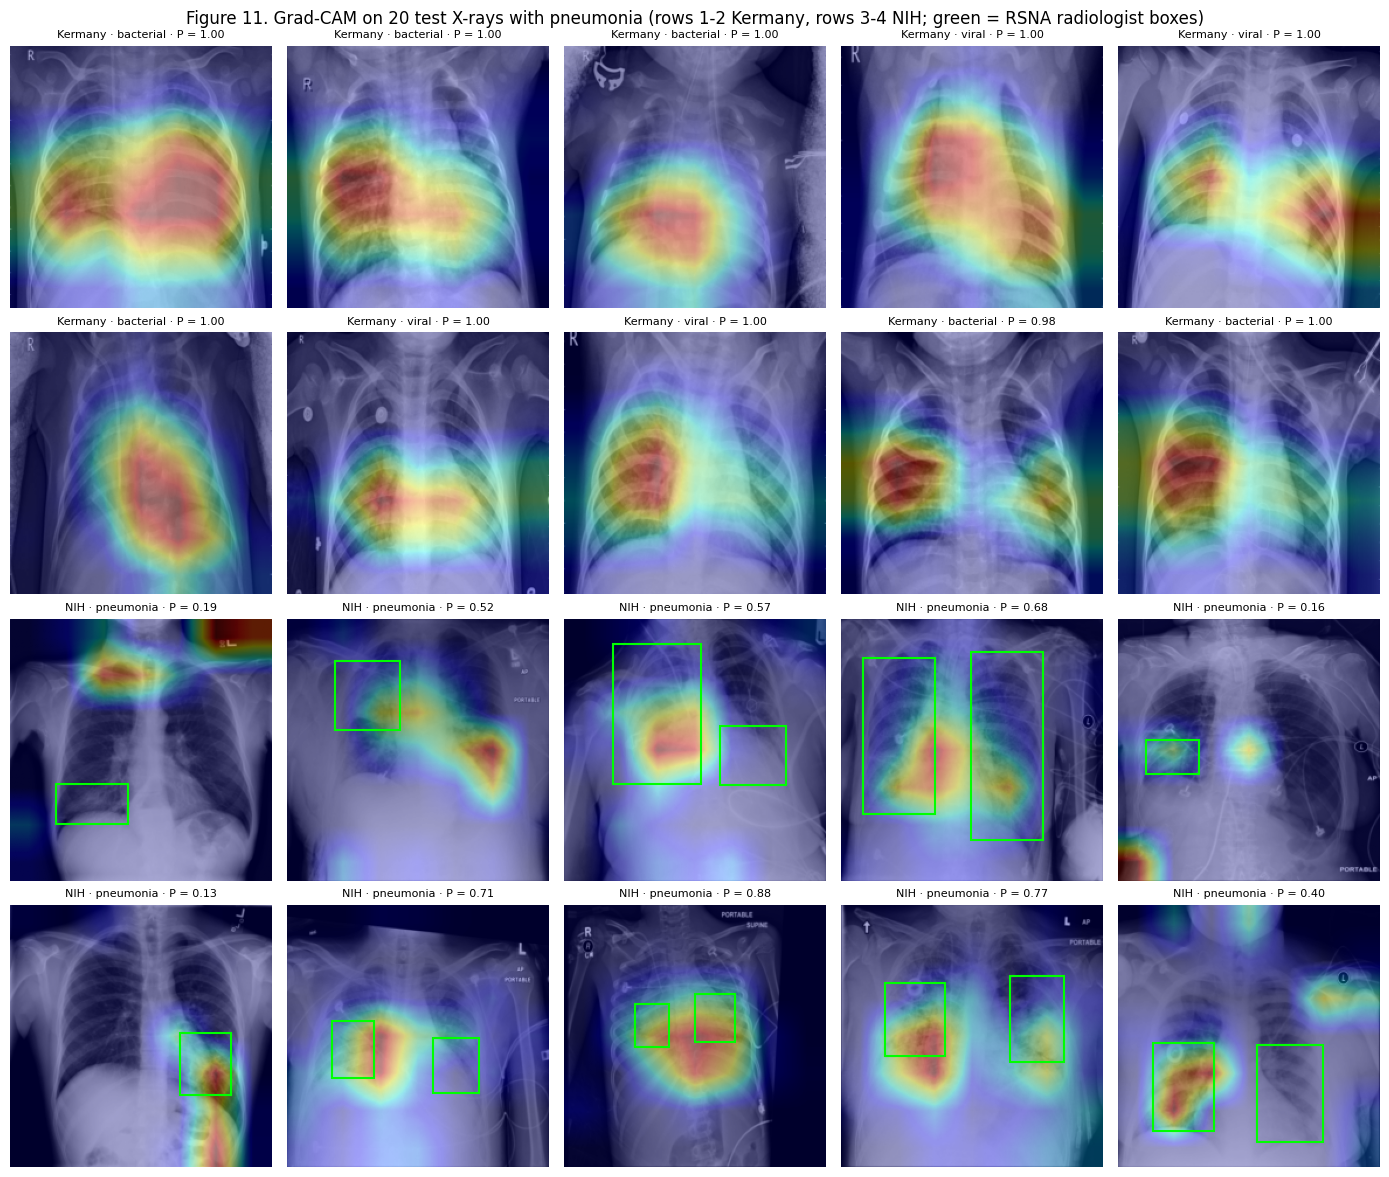

In [37]:
# 20 examples for manual inspection (proposal: "the map covers the lung region for the majority of 20 examples").
rng = np.random.default_rng(SEED)
ker_pos = manifest[(manifest.split == "test") & (manifest.source == "Kermany") & (manifest.label == 1)]
nih_pos = box_rows if len(box_rows) else manifest[(manifest.split == "test") & (manifest.source == "NIH") & (manifest.label == 1)]
gallery = pd.concat([ker_pos.sample(n=min(10, len(ker_pos)), random_state=SEED),
                     nih_pos.sample(n=min(10, len(nih_pos)), random_state=SEED)])
cams, _ = grad_cam(cam_model, as_input(gallery.cache_idx))
fig, axes = plt.subplots(4, 5, figsize=(14, 12))
for ax in axes.ravel():
    ax.axis("off")
for ax, (_, row), cam in zip(axes.ravel(), gallery.iterrows(), cams):
    p = SCORES[manifest.index.get_loc(row.name)]
    show_cam(ax, row.cache_idx, cam, f"{row.source} · {row.subtype} · P = {p:.2f}", BOXES.get(row.image_id, ()))
fig.suptitle(f"Figure {FIG_NO}. Grad-CAM on 20 test X-rays with pneumonia (rows 1-2 Kermany, rows 3-4 NIH; "
             f"green = RSNA radiologist boxes)")
plt.tight_layout()
plt.show()

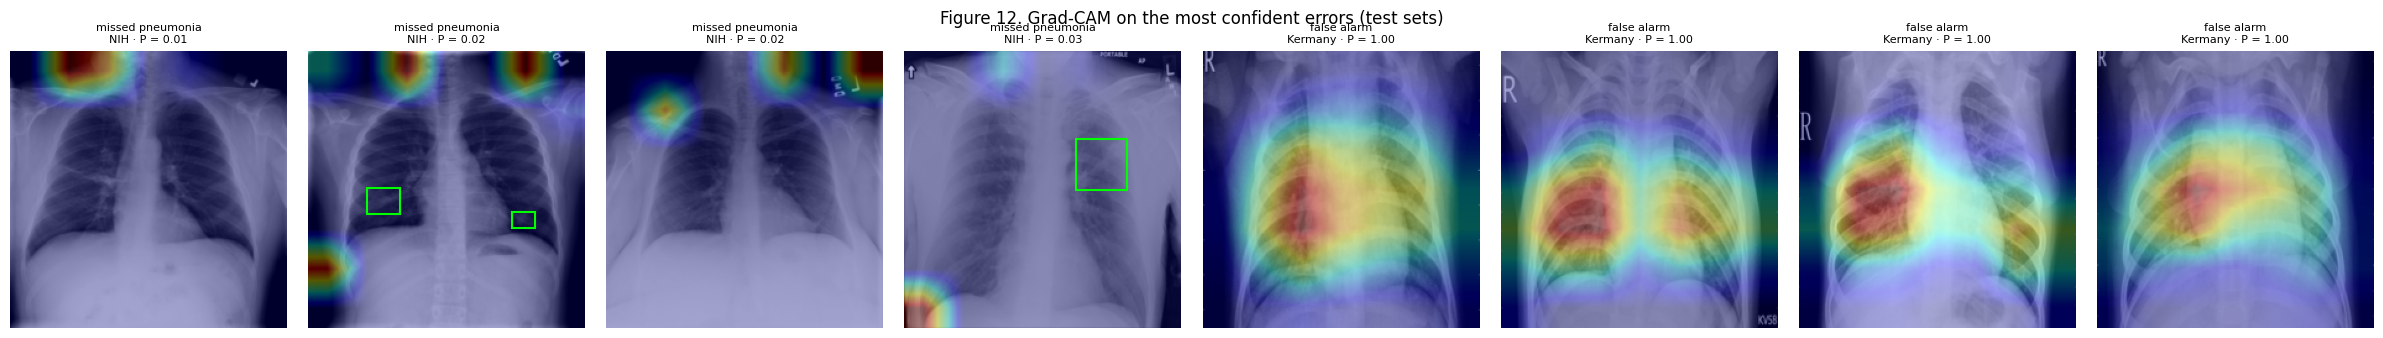

In [38]:
# Mistakes are the most instructive: what did the model look at when it was wrong?
t = CNN[MAIN]["thresholds"]
test_rows = manifest[manifest.split == "test"].copy()
test_rows["p"] = SCORES[test_rows.index]
test_rows["t"] = np.where(test_rows.source == "NIH", t["test NIH"], t["test Kermany"])
fn = test_rows[(test_rows.label == 1) & (test_rows.p < test_rows.t)].nsmallest(4, "p")
fp = test_rows[(test_rows.label == 0) & (test_rows.p >= test_rows.t)].nlargest(4, "p")
errors = pd.concat([fn.assign(kind="missed pneumonia"), fp.assign(kind="false alarm")])
if len(errors):
    cams, _ = grad_cam(cam_model, as_input(errors.cache_idx))
    fig, axes = plt.subplots(1, len(errors), figsize=(3 * len(errors), 3.4), squeeze=False)
    for ax, (_, row), cam in zip(axes[0], errors.iterrows(), cams):
        show_cam(ax, row.cache_idx, cam, f"{row.kind}\n{row.source} · P = {row.p:.2f}", BOXES.get(row.image_id, ()))
    fig.suptitle(f"Figure {FIG_NO + 1}. Grad-CAM on the most confident errors (test sets)")
    plt.tight_layout()
    plt.show()

## 12. Three classes: Normal / Bacterial / Viral pneumonia (N1)

Only the Kermany images say *which* pneumonia it is (`person123_bacteria_456.jpeg`, `person7_virus_15.jpeg`), so this
model is trained and tested on Kermany alone, with the same patient-wise splits. Instead of ImageNet weights, the
backbone starts from the binary model of section 10: its features have already been adapted to chest X-rays
(transfer learning from a related task). The head is a 3-way softmax; the loss is sparse categorical cross-entropy
with balanced class weights (viral cases are the minority).

Telling bacterial from viral pneumonia on an X-ray is hard even for radiologists, so the proposal target is modest:
macro-F1 ≥ 0.75 and recall of the viral class ≥ 0.60.

In [39]:
CLASSES3 = ["normal", "bacterial", "viral"]
k3 = manifest[(manifest.source == "Kermany") & manifest.subtype.isin(CLASSES3)].copy()
k3["label3"] = k3.subtype.map({c: i for i, c in enumerate(CLASSES3)})
LABEL3_BY_IDX = np.full(len(IMAGES), -1, dtype=np.int32)
LABEL3_BY_IDX[k3.cache_idx.to_numpy()] = k3.label3.to_numpy()
display(pd.crosstab(k3.split, k3.subtype).reindex(index=["train", "val", "test"], columns=CLASSES3))


def make_dataset3(split, training=False):
    rows = k3[k3.split == split]
    ds = tf.data.Dataset.from_tensor_slices(rows.cache_idx.to_numpy())
    if training:
        ds = ds.shuffle(len(rows), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.map(lambda i: tf.numpy_function(lambda j: (IMAGES[np.sort(j)], LABEL3_BY_IDX[np.sort(j)]), [i],
                                            (tf.uint8, tf.int32)), num_parallel_calls=AUTOTUNE)
    return ds.map(_to_model_input, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)


train3_ds, val3_ds, test3_ds = make_dataset3("train", training=True), make_dataset3("val"), make_dataset3("test")
w3 = compute_class_weight("balanced", classes=np.arange(3), y=k3.loc[k3.split == "train", "label3"])
CLASS_WEIGHT3 = {i: float(w) for i, w in enumerate(w3)}
print("Class weights:", {CLASSES3[i]: round(w, 3) for i, w in CLASS_WEIGHT3.items()})

subtype,normal,bacterial,viral
split,,,
train,1156,2140,1179
val,193,398,166
test,234,242,148


Class weights: {'normal': 1.29, 'bacterial': 0.697, 'viral': 1.265}


Epoch 1/3

Epoch 1: val_loss improved from None to 0.49349, saving model to /kaggle/working/pneumodetect_resnet50_3class_best.keras

Epoch 1: finished saving model to /kaggle/working/pneumodetect_resnet50_3class_best.keras
140/140 - 29s - 208ms/step - accuracy: 0.6985 - loss: 0.5649 - val_accuracy: 0.8045 - val_loss: 0.4935 - learning_rate: 0.0010
Epoch 2/3

Epoch 2: val_loss did not improve from 0.49349
140/140 - 16s - 112ms/step - accuracy: 0.7672 - loss: 0.4552 - val_accuracy: 0.7688 - val_loss: 0.5533 - learning_rate: 0.0010
Epoch 3/3

Epoch 3: val_loss did not improve from 0.49349

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
140/140 - 16s - 112ms/step - accuracy: 0.7721 - loss: 0.4445 - val_accuracy: 0.7622 - val_loss: 0.5552 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 1.
Epoch 1/10

Epoch 1: val_loss did not improve from 0.49349
140/140 - 30s - 211ms/step - accuracy: 0.7613 - loss: 0.4565 - val_accuracy: 0.8151 

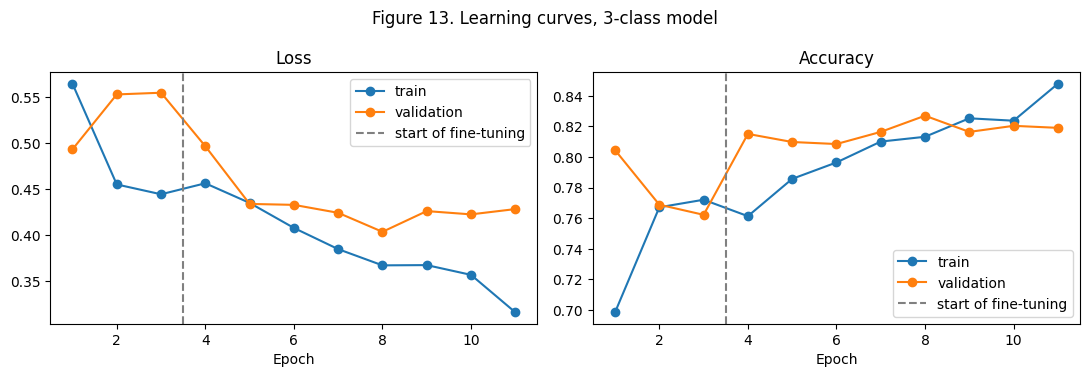

In [40]:
STAGE1_EPOCHS_3 = int(os.environ.get("PNEUMODETECT_STAGE1_EPOCHS", 3))
STAGE2_EPOCHS_3 = int(os.environ.get("PNEUMODETECT_STAGE2_EPOCHS", 10))
CKPT3 = WORK_DIR / f"pneumodetect_{MAIN}_3class_best.keras"
LOGS3 = [WORK_DIR / f"history_{MAIN}_3class_stage{s}.csv" for s in (1, 2)]


def build_model3():
    binary = CNN[MAIN]["model"]
    _, src_base, _ = split_model(binary)
    constructor, preprocessing, last_block = BACKBONES[MAIN]
    inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3), name="xray")
    x = make_augmentation()(inputs)
    if preprocessing == "caffe":
        x = tf.keras.layers.Normalization(mean=[103.939, 116.779, 123.68], variance=[1.0, 1.0, 1.0],
                                          name="imagenet_preprocessing")(x)
    base = constructor(weights=None, include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.set_weights(src_base.get_weights())                 # start from the X-ray-adapted backbone
    base.trainable = False
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = tf.keras.layers.Dropout(DROPOUT, name="dropout")(x)
    outputs = tf.keras.layers.Dense(3, activation="softmax", dtype="float32", name="p_class")(x)
    return tf.keras.Model(inputs, outputs, name=f"pneumodetect_{MAIN}_3class"), base, last_block


def compile3(model, lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])


def callbacks3(stage, best_loss=None):
    return [
        tf.keras.callbacks.ModelCheckpoint(CKPT3, monitor="val_loss", mode="min", save_best_only=True,
                                           initial_value_threshold=best_loss, verbose=1),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7, verbose=1),
        tf.keras.callbacks.CSVLogger(LOGS3[stage - 1]),
    ]


t0 = time.time()
if REUSE_CHECKPOINTS and CKPT3.exists() and all(p.exists() for p in LOGS3):
    print("Reusing", CKPT3.name)
else:
    model3, base3, last_block3 = build_model3()
    compile3(model3, STAGE1_LR)
    h1 = model3.fit(train3_ds, validation_data=val3_ds, epochs=STAGE1_EPOCHS_3, class_weight=CLASS_WEIGHT3,
                    shuffle=False, callbacks=callbacks3(1), verbose=2)
    unfreeze_last_block(base3, last_block3)
    compile3(model3, STAGE2_LR)
    model3.fit(train3_ds, validation_data=val3_ds, epochs=STAGE2_EPOCHS_3, class_weight=CLASS_WEIGHT3,
               shuffle=False, callbacks=callbacks3(2, best_loss=min(h1.history["val_loss"])), verbose=2)
model3 = tf.keras.models.load_model(CKPT3)
history3 = pd.concat([pd.read_csv(p).assign(stage=s) for s, p in enumerate(LOGS3, start=1)], ignore_index=True)
print(f"3-class model ready in {(time.time() - t0) / 60:.1f} min")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
epochs = np.arange(1, len(history3) + 1)
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(epochs, history3[metric], "o-", label="train")
    ax.plot(epochs, history3["val_" + metric], "o-", label="validation")
    ax.axvline((history3.stage == 1).sum() + 0.5, color="gray", ls="--", label="start of fine-tuning")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_xlabel("Epoch")
    ax.set_title(metric.capitalize())
    ax.legend()
fig.suptitle(f"Figure {FIG_NO + 2}. Learning curves, 3-class model")
plt.tight_layout()
plt.show()

Table 5. 3-class model on the Kermany test set


,precision,recall,f1-score,support
normal,0.956,0.739,0.834,234.0
bacterial,0.819,0.950,0.880,242.0
viral,0.691,0.757,0.723,148.0
macro avg,0.822,0.815,0.812,624.0
weighted avg,0.840,0.825,0.825,624.0


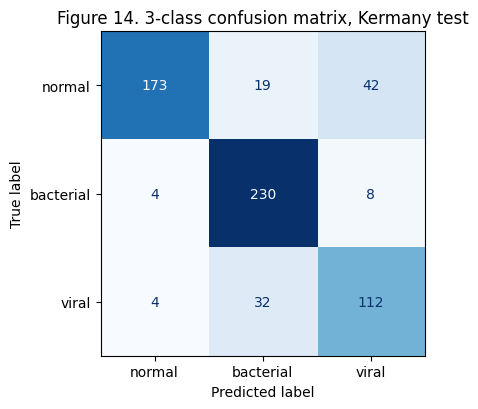

Table 6. Success criteria for the 3-class model (proposal, nice-to-do)


,Criterion,Target,Result,Met
0,"Macro-F1 (Normal / Bacterial / Viral), test",≥ 0.75,0.812,yes
1,"Recall of the viral class, test",≥ 0.60,0.757,yes
2,Macro-F1 drop validation → test,reported,-0.007,—


In [41]:
from sklearn.metrics import classification_report

reports = {}
for split, ds in (("val", val3_ds), ("test", test3_ds)):
    y_true, probs = [], []
    for x, y in ds:
        probs.append(model3(x, training=False).numpy())
        y_true.append(y.numpy())
    y_true, probs = np.concatenate(y_true), np.concatenate(probs)
    reports[split] = (y_true, probs)

y_true, probs = reports["test"]
y_pred = probs.argmax(1)
report = pd.DataFrame(classification_report(y_true, y_pred, labels=[0, 1, 2], target_names=CLASSES3,
                                            output_dict=True, zero_division=0)).T.drop(index="accuracy").round(3)
print("Table 5. 3-class model on the Kermany test set")
display(report)

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=[0, 1, 2], display_labels=CLASSES3, cmap="Blues",
                                        colorbar=False, ax=ax)
ax.set_title(f"Figure {FIG_NO + 3}. 3-class confusion matrix, Kermany test")
plt.tight_layout()
plt.show()

macro_f1 = {s: f1_score(y, p.argmax(1), labels=[0, 1, 2], average="macro", zero_division=0) for s, (y, p) in reports.items()}
viral_recall = recall_score(y_true, y_pred, labels=[2], average="macro", zero_division=0)
criteria3 = pd.DataFrame([
    ("Macro-F1 (Normal / Bacterial / Viral), test", "≥ 0.75", macro_f1["test"], macro_f1["test"] >= 0.75),
    ("Recall of the viral class, test", "≥ 0.60", viral_recall, viral_recall >= 0.60),
    ("Macro-F1 drop validation → test", "reported", macro_f1["val"] - macro_f1["test"], None),
], columns=["Criterion", "Target", "Result", "Met"])
criteria3["Result"] = criteria3.Result.round(3)
criteria3["Met"] = criteria3.Met.map({True: "yes", False: "no"}).fillna("—")
print("Table 6. Success criteria for the 3-class model (proposal, nice-to-do)")
display(criteria3)
criteria3.to_csv(WORK_DIR / "success_criteria_3class.csv", index=False)

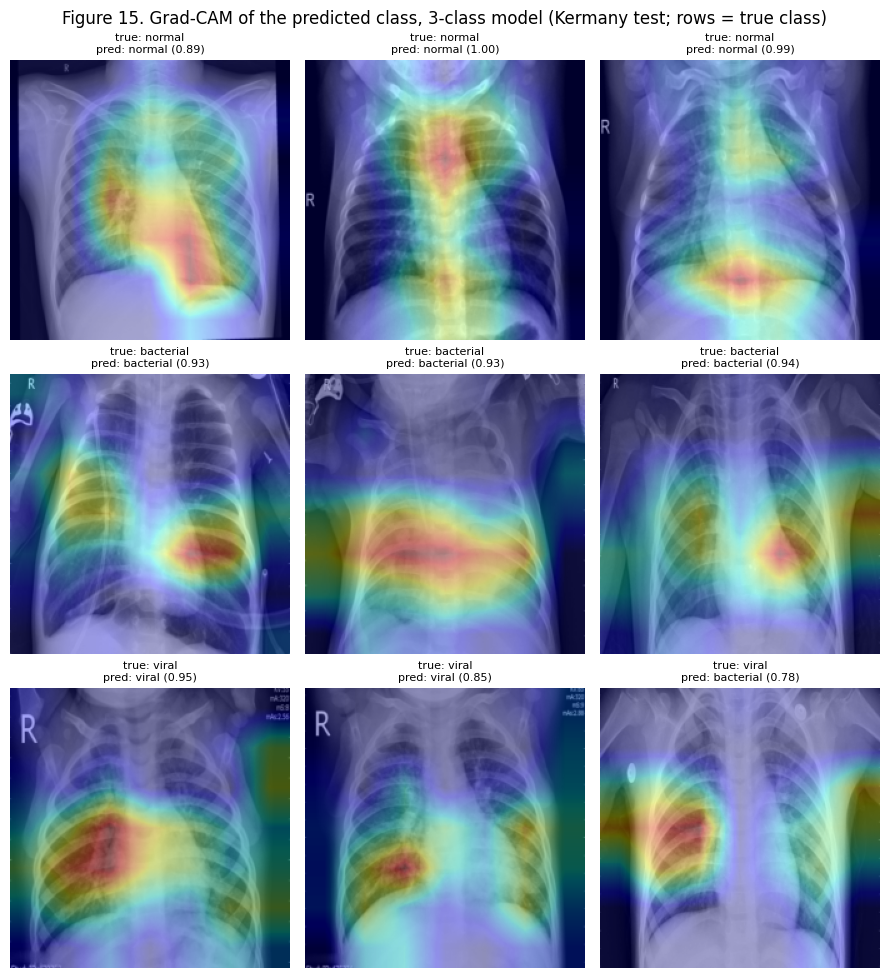

In [42]:
# Grad-CAM for the 3-class model: where does it look when it decides "viral" vs "bacterial"?
test3 = k3[k3.split == "test"]
picks = pd.concat([test3[test3.subtype == c].sample(n=min(3, (test3.subtype == c).sum()), random_state=SEED)
                   for c in CLASSES3])
cams, out = grad_cam(model3, as_input(picks.cache_idx))
fig, axes = plt.subplots(3, 3, figsize=(9, 10))
for ax in axes.ravel():
    ax.axis("off")
for ax, (_, row), cam, p in zip(axes.ravel(), picks.iterrows(), cams, out):
    show_cam(ax, row.cache_idx, cam, f"true: {row.subtype}\npred: {CLASSES3[p.argmax()]} ({p.max():.2f})")
fig.suptitle(f"Figure {FIG_NO + 4}. Grad-CAM of the predicted class, 3-class model (Kermany test; rows = true class)")
plt.tight_layout()
plt.show()

## 13. Demo application (N3)

The trained models saved above (`pneumodetect_resnet50_best.keras`, `pneumodetect_resnet50_3class_best.keras`) are
used by the separate notebook **`Pneumodetect_App.ipynb`**: a Gradio web page where the user uploads an X-ray and
gets P(pneumonia), the likely type (bacterial / viral), the "low confidence" flag for 0.40–0.60 and the Grad-CAM
overlay. Keeping the application apart means it starts in seconds and never retrains the models.